In [1]:
import os
import random
import numpy as np
import pandas as pd
import torch
import transformers
import sklearn

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MODEL_NAME = "gpt2-medium"
MONITORED_LAYERS = [3, 4, 5, 6]

MAX_NEW_TOKENS = 32
TEMPERATURE = 0.7
TOP_P = 0.9

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Scikit-learn:", sklearn.__version__)
print("NumPy:", np.__version__)
print("Device:", DEVICE)
print("Model:", MODEL_NAME)
print("Layers:", MONITORED_LAYERS)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
Transformers: 5.18.0
Scikit-learn: 1.6.1
NumPy: 2.1.3
Device: cuda
Model: gpt2-medium
Layers: [3, 4, 5, 6]
GPU: Tesla T4


In [2]:
from transformers import AutoTokenizer, AutoModelForCausalLM

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    output_hidden_states=True
).to(DEVICE)

model.eval()

for param in model.parameters():
    param.requires_grad = False

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)
print("Frozen:", trainable_params == 0)

config.json:   0%|          | 0.00/718 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.52GB            

model.safetensors: downloading bytes:           |  0.00B            

[transformers] The following generation flags are not valid and may be ignored: ['output_hidden_states']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Loading weights:   0%|          | 0/292 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Total parameters: 354823168
Trainable parameters: 0
Frozen: True


In [3]:
test_prompt = "Question: What is the capital of France?\nAnswer:"

inputs = tokenizer(
    test_prompt,
    return_tensors="pt"
).to(DEVICE)

with torch.no_grad():
    outputs = model(
        **inputs,
        output_hidden_states=True
    )

print("Input tokens:", inputs["input_ids"].shape[1])
print("Hidden-state sets:", len(outputs.hidden_states))
print("Layer 3 shape:", tuple(outputs.hidden_states[3].shape))
print("Layer 6 shape:", tuple(outputs.hidden_states[6].shape))

Input tokens: 12
Hidden-state sets: 25
Layer 3 shape: (1, 12, 1024)
Layer 6 shape: (1, 12, 1024)


In [4]:
def controlled_generate(
    prompt,
    max_new_tokens=32,
    temperature=0.7,
    top_p=0.9
):
    inputs = tokenizer(
        prompt,
        return_tensors="pt"
    ).to(DEVICE)

    generated_ids = inputs["input_ids"].clone()

    for _ in range(max_new_tokens):
        with torch.no_grad():
            outputs = model(
                input_ids=generated_ids,
                attention_mask=torch.ones_like(generated_ids),
                output_hidden_states=True
            )

        logits = outputs.logits[:, -1, :] / temperature

        sorted_logits, sorted_indices = torch.sort(
            logits,
            descending=True
        )

        sorted_probs = torch.softmax(
            sorted_logits,
            dim=-1
        )

        cumulative_probs = torch.cumsum(
            sorted_probs,
            dim=-1
        )

        mask = cumulative_probs > top_p
        mask[..., 1:] = mask[..., :-1].clone()
        mask[..., 0] = False

        sorted_logits[mask] = float("-inf")

        filtered_logits = torch.full_like(
            logits,
            float("-inf")
        )

        filtered_logits.scatter_(
            1,
            sorted_indices,
            sorted_logits
        )

        probs = torch.softmax(
            filtered_logits,
            dim=-1
        )

        next_token = torch.multinomial(
            probs,
            num_samples=1
        )

        generated_ids = torch.cat(
            [generated_ids, next_token],
            dim=1
        )

        if next_token.item() == tokenizer.eos_token_id:
            break

    generated_ids = generated_ids[
        0,
        inputs["input_ids"].shape[1]:
    ]

    return tokenizer.decode(
        generated_ids,
        skip_special_tokens=True
    ).strip()

In [5]:
prompts = [
    "Question: What is the capital of France?\nAnswer:",
    "Question: What is 2 + 2?\nAnswer:",
    "Question: Who was the first person to walk on the Moon?\nAnswer:"
]

for prompt in prompts:
    output = controlled_generate(prompt)
    print("=" * 60)
    print("PROMPT:", prompt)
    print("OUTPUT:", output)

PROMPT: Question: What is the capital of France?
Answer:
OUTPUT: It is the value of the French franc.
It is hard to find out what value is supposed to be in France because there are no official prices for goods
PROMPT: Question: What is 2 + 2?
Answer:
OUTPUT: 2 + 2 is a 2 + 2.
I'm not sure why there's such confusion about what 2 + 2 means, but I think I understand.
PROMPT: Question: Who was the first person to walk on the Moon?
Answer:
OUTPUT: The first person to walk on the Moon was Yuri Gagarin, in July 1961. He was only 16 years old.
Question: Who was the first


In [6]:
def extract_trajectory(
    prompt,
    max_new_tokens=32,
    temperature=0.7,
    top_p=0.9
):
    inputs = tokenizer(
        prompt,
        return_tensors="pt"
    ).to(DEVICE)

    generated_ids = inputs["input_ids"].clone()
    records = []
    previous_hidden = {
        layer: None for layer in MONITORED_LAYERS
    }

    for step in range(1, max_new_tokens + 1):
        with torch.no_grad():
            outputs = model(
                input_ids=generated_ids,
                attention_mask=torch.ones_like(generated_ids),
                output_hidden_states=True
            )

        logits = outputs.logits[:, -1, :] / temperature

        sorted_logits, sorted_indices = torch.sort(
            logits,
            descending=True
        )

        sorted_probs = torch.softmax(
            sorted_logits,
            dim=-1
        )

        cumulative_probs = torch.cumsum(
            sorted_probs,
            dim=-1
        )

        mask = cumulative_probs > top_p
        mask[..., 1:] = mask[..., :-1].clone()
        mask[..., 0] = False

        sorted_logits[mask] = float("-inf")

        filtered_logits = torch.full_like(
            logits,
            float("-inf")
        )

        filtered_logits.scatter_(
            1,
            sorted_indices,
            sorted_logits
        )

        probs = torch.softmax(
            filtered_logits,
            dim=-1
        )

        next_token = torch.multinomial(
            probs,
            num_samples=1
        )

        token_id = next_token.item()
        token = tokenizer.decode([token_id])

        token_probability = probs[0, token_id].item()

        entropy = -torch.sum(
            probs * torch.log(probs + 1e-12)
        ).item()

        normalized_entropy = (
            entropy / np.log(probs.shape[-1])
        )

        row = {
            "step": step,
            "token": token,
            "token_id": token_id,
            "token_probability": token_probability,
            "entropy": entropy,
            "normalized_entropy": normalized_entropy
        }

        for layer in MONITORED_LAYERS:
            h = outputs.hidden_states[layer][0, -1, :]

            norm = torch.norm(h).item()

            if previous_hidden[layer] is None:
                delta = np.nan
                cosine = np.nan
            else:
                delta = torch.norm(
                    h - previous_hidden[layer]
                ).item()

                cosine = torch.nn.functional.cosine_similarity(
                    h.unsqueeze(0),
                    previous_hidden[layer].unsqueeze(0)
                ).item()

            row[f"L{layer}_norm"] = norm
            row[f"L{layer}_delta"] = delta
            row[f"L{layer}_cosine"] = cosine

            previous_hidden[layer] = h.detach().clone()

        records.append(row)

        generated_ids = torch.cat(
            [generated_ids, next_token],
            dim=1
        )

        if token_id == tokenizer.eos_token_id:
            break

    trajectory = pd.DataFrame(records)

    generated_tokens = generated_ids[
        0,
        inputs["input_ids"].shape[1]:
    ]

    generated_text = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    ).strip()

    return generated_text, trajectory

In [7]:
prompt = "Question: What is the capital of France?\nAnswer:"

generated_text, trajectory = extract_trajectory(prompt)

print("GENERATED:")
print(generated_text)

print("\nTRAJECTORY:")
display(trajectory.head(10))

GENERATED:
It is the same as the French Republic, which is the oldest country in the world.
Answer: The capital of France is Paris.
Answer: The

TRAJECTORY:


,step,token,token_id,token_probability,entropy,normalized_entropy,L3_norm,L3_delta,L3_cosine,L4_norm,L4_delta,L4_cosine,L5_norm,L5_delta,L5_cosine,L6_norm,L6_delta,L6_cosine
0,1,It,632,0.095011,1.883386,0.173986,121.983887,NaN,NaN,124.934937,NaN,NaN,135.964066,NaN,NaN,144.220520,NaN,NaN
1,2,is,318,0.904302,0.315526,0.029148,128.107117,48.024780,0.927405,130.302643,53.535500,0.912858,140.951508,61.583168,0.901702,144.545517,65.871483,0.895931
2,3,the,262,0.696785,1.454552,0.134371,127.004234,45.004173,0.937795,127.538315,49.321041,0.927042,132.257599,56.630394,0.916011,137.010742,60.989689,0.907521
3,4,same,976,0.017024,2.591872,0.239436,122.328857,36.701035,0.957354,126.301514,40.871273,0.948197,127.225548,45.554657,0.939087,130.190811,51.269367,0.927624
4,5,as,355,0.941567,0.222634,0.020567,131.930374,62.131485,0.883259,137.675278,68.224831,0.869878,143.894836,72.886658,0.862496,152.652039,79.245560,0.854700
5,6,the,262,0.406869,1.344658,0.124219,127.307838,65.827507,0.871638,131.574600,73.147202,0.853342,145.025894,81.800552,0.839709,150.488800,85.847244,0.839697
6,7,French,4141,0.019023,0.094211,0.008703,121.252182,41.420238,0.945616,121.533981,48.289772,0.930238,128.750610,56.362076,0.922028,133.905502,60.013889,0.917458
7,8,Republic,2066,0.091372,2.284559,0.211047,148.298355,72.005951,0.876168,161.265869,80.445297,0.875178,173.396439,87.467773,0.873295,178.715912,90.659981,0.870226
8,9,",",11,0.378708,0.888298,0.082061,138.511581,85.169701,0.825761,150.093933,93.528625,0.821880,161.439621,99.636559,0.825234,165.953644,104.513039,0.818600
9,10,which,543,0.202990,2.049581,0.189339,122.537354,66.672577,0.876566,122.917023,74.363495,0.870147,128.341446,80.714760,0.869219,134.500046,85.617264,0.857958


In [8]:
trajectory["relative_delta_L3"] = trajectory["L3_delta"] / (
    trajectory["L3_norm"].shift(1) + 1e-8
)

trajectory["relative_delta_L4"] = trajectory["L4_delta"] / (
    trajectory["L4_norm"].shift(1) + 1e-8
)

trajectory["relative_delta_L5"] = trajectory["L5_delta"] / (
    trajectory["L5_norm"].shift(1) + 1e-8
)

trajectory["relative_delta_L6"] = trajectory["L6_delta"] / (
    trajectory["L6_norm"].shift(1) + 1e-8
)

display(
    trajectory[
        [
            "step",
            "token",
            "token_probability",
            "entropy",
            "L3_delta",
            "L4_delta",
            "L5_delta",
            "L6_delta",
            "relative_delta_L3",
            "relative_delta_L4",
            "relative_delta_L5",
            "relative_delta_L6"
        ]
    ].head(10)
)

,step,token,token_probability,entropy,L3_delta,L4_delta,L5_delta,L6_delta,relative_delta_L3,relative_delta_L4,relative_delta_L5,relative_delta_L6
0,1,It,0.095011,1.883386,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,is,0.904302,0.315526,48.024780,53.535500,61.583168,65.871483,0.393698,0.428507,0.452937,0.456741
2,3,the,0.696785,1.454552,45.004173,49.321041,56.630394,60.989689,0.351301,0.378511,0.401772,0.421941
3,4,same,0.017024,2.591872,36.701035,40.871273,45.554657,51.269367,0.288975,0.320463,0.344439,0.374200
4,5,as,0.941567,0.222634,62.131485,68.224831,72.886658,79.245560,0.507905,0.540174,0.572893,0.608688
5,6,the,0.406869,1.344658,65.827507,73.147202,81.800552,85.847244,0.498956,0.531302,0.568475,0.562372
6,7,French,0.019023,0.094211,41.420238,48.289772,56.362076,60.013889,0.325355,0.367014,0.388635,0.398793
7,8,Republic,0.091372,2.284559,72.005951,80.445297,87.467773,90.659981,0.593853,0.661916,0.679358,0.677044
8,9,",",0.378708,0.888298,85.169701,93.528625,99.636559,104.513039,0.574313,0.579965,0.574617,0.584800
9,10,which,0.202990,2.049581,66.672577,74.363495,80.714760,85.617264,0.481350,0.495446,0.499969,0.515911


In [9]:
trajectory["mean_relative_delta"] = trajectory[
    [
        "relative_delta_L3",
        "relative_delta_L4",
        "relative_delta_L5",
        "relative_delta_L6"
    ]
].mean(axis=1)

trajectory["mean_layer_norm"] = trajectory[
    [
        "L3_norm",
        "L4_norm",
        "L5_norm",
        "L6_norm"
    ]
].mean(axis=1)

display(
    trajectory[
        [
            "step",
            "token",
            "token_probability",
            "entropy",
            "mean_relative_delta",
            "mean_layer_norm"
        ]
    ].head(10)
)

,step,token,token_probability,entropy,mean_relative_delta,mean_layer_norm
0,1,It,0.095011,1.883386,NaN,131.775852
1,2,is,0.904302,0.315526,0.432971,135.976696
2,3,the,0.696785,1.454552,0.388381,130.952723
3,4,same,0.017024,2.591872,0.332019,126.511683
4,5,as,0.941567,0.222634,0.557415,141.538132
5,6,the,0.406869,1.344658,0.540276,138.599283
6,7,French,0.019023,0.094211,0.369949,126.360569
7,8,Republic,0.091372,2.284559,0.653043,165.419144
8,9,",",0.378708,0.888298,0.578424,153.999695
9,10,which,0.202990,2.049581,0.498169,127.073967


In [10]:
trajectory["uncertainty_score"] = (
    trajectory["entropy"] +
    (1 - trajectory["token_probability"])
) / 2

trajectory["trajectory_score"] = (
    trajectory["mean_relative_delta"] +
    trajectory["uncertainty_score"]
) / 2

display(
    trajectory[
        [
            "step",
            "token",
            "token_probability",
            "entropy",
            "mean_relative_delta",
            "uncertainty_score",
            "trajectory_score"
        ]
    ].head(10)
)

,step,token,token_probability,entropy,mean_relative_delta,uncertainty_score,trajectory_score
0,1,It,0.095011,1.883386,NaN,1.394187,NaN
1,2,is,0.904302,0.315526,0.432971,0.205612,0.319291
2,3,the,0.696785,1.454552,0.388381,0.878883,0.633632
3,4,same,0.017024,2.591872,0.332019,1.787424,1.059722
4,5,as,0.941567,0.222634,0.557415,0.140533,0.348974
5,6,the,0.406869,1.344658,0.540276,0.968894,0.754585
6,7,French,0.019023,0.094211,0.369949,0.537594,0.453772
7,8,Republic,0.091372,2.284559,0.653043,1.596593,1.124818
8,9,",",0.378708,0.888298,0.578424,0.754795,0.666609
9,10,which,0.202990,2.049581,0.498169,1.423296,0.960732


In [11]:
trajectory["anomaly_signal"] = (
    trajectory["mean_relative_delta"]
    .rolling(window=3, min_periods=1)
    .mean()
)

display(
    trajectory[
        [
            "step",
            "token",
            "trajectory_score",
            "anomaly_signal"
        ]
    ].head(15)
)

,step,token,trajectory_score,anomaly_signal
0,1,It,NaN,NaN
1,2,is,0.319291,0.432971
2,3,the,0.633632,0.410676
3,4,same,1.059722,0.384457
4,5,as,0.348974,0.425939
5,6,the,0.754585,0.476570
6,7,French,0.453772,0.489214
7,8,Republic,1.124818,0.521089
8,9,",",0.666609,0.533805
9,10,which,0.960732,0.576545


In [12]:
trajectory_stats = trajectory[
    [
        "step",
        "token",
        "token_probability",
        "entropy",
        "normalized_entropy",
        "mean_relative_delta",
        "mean_layer_norm",
        "mean_relative_delta"
    ]
].copy()

display(trajectory_stats.describe())

,step,token_probability,entropy,normalized_entropy,mean_relative_delta,mean_layer_norm,mean_relative_delta
count,32.000000,32.000000,32.000000,32.000000,31.000000,32.000000,31.000000
mean,16.500000,0.593275,0.977906,0.090339,0.492378,138.973896,0.492378
std,9.380832,0.358973,0.953330,0.088068,0.118090,14.662269,0.118090
min,1.000000,0.013158,-0.000000,-0.000000,0.300391,123.161160,0.300391
25%,8.750000,0.250377,0.190528,0.017601,0.399990,127.975732,0.399990
50%,16.500000,0.677960,0.729529,0.067394,0.503715,131.493503,0.503715
75%,24.250000,0.913618,1.536363,0.141929,0.583025,149.209244,0.583025
max,32.000000,1.000000,3.707559,0.342503,0.691615,168.332176,0.691615


In [13]:
feature_columns = [
    "token_probability",
    "entropy",
    "normalized_entropy",
    "mean_relative_delta",
    "mean_layer_norm",
    "L3_delta",
    "L4_delta",
    "L5_delta",
    "L6_delta",
    "L3_cosine",
    "L4_cosine",
    "L5_cosine",
    "L6_cosine"
]

token_features = trajectory[
    ["step", "token"] + feature_columns
].copy()

token_features = token_features.dropna().reset_index(drop=True)

print("Rows:", len(token_features))
print("Features:", len(feature_columns))

display(token_features.head(10))

Rows: 31
Features: 13


,step,token,token_probability,entropy,normalized_entropy,mean_relative_delta,mean_layer_norm,L3_delta,L4_delta,L5_delta,L6_delta,L3_cosine,L4_cosine,L5_cosine,L6_cosine
0,2,is,0.904302,0.315526,0.029148,0.432971,135.976696,48.024780,53.535500,61.583168,65.871483,0.927405,0.912858,0.901702,0.895931
1,3,the,0.696785,1.454552,0.134371,0.388381,130.952723,45.004173,49.321041,56.630394,60.989689,0.937795,0.927042,0.916011,0.907521
2,4,same,0.017024,2.591872,0.239436,0.332019,126.511683,36.701035,40.871273,45.554657,51.269367,0.957354,0.948197,0.939087,0.927624
3,5,as,0.941567,0.222634,0.020567,0.557415,141.538132,62.131485,68.224831,72.886658,79.245560,0.883259,0.869878,0.862496,0.854700
4,6,the,0.406869,1.344658,0.124219,0.540276,138.599283,65.827507,73.147202,81.800552,85.847244,0.871638,0.853342,0.839709,0.839697
5,7,French,0.019023,0.094211,0.008703,0.369949,126.360569,41.420238,48.289772,56.362076,60.013889,0.945616,0.930238,0.922028,0.917458
6,8,Republic,0.091372,2.284559,0.211047,0.653043,165.419144,72.005951,80.445297,87.467773,90.659981,0.876168,0.875178,0.873295,0.870226
7,9,",",0.378708,0.888298,0.082061,0.578424,153.999695,85.169701,93.528625,99.636559,104.513039,0.825761,0.821880,0.825234,0.818600
8,10,which,0.202990,2.049581,0.189339,0.498169,127.073967,66.672577,74.363495,80.714760,85.617264,0.876566,0.870147,0.869219,0.857958
9,11,is,0.730968,0.877517,0.081065,0.411598,132.695068,46.439625,50.563046,53.958515,58.590881,0.929336,0.920678,0.918812,0.910408


In [14]:
response_features = {}

for column in feature_columns:
    response_features[f"{column}_mean"] = token_features[column].mean()
    response_features[f"{column}_std"] = token_features[column].std()
    response_features[f"{column}_max"] = token_features[column].max()
    response_features[f"{column}_min"] = token_features[column].min()

response_features["num_tokens"] = len(token_features)

response_feature_df = pd.DataFrame([response_features])

print("Response feature shape:", response_feature_df.shape)

display(response_feature_df.T)

Response feature shape: (1, 53)


,0
token_probability_mean,0.609348
token_probability_std,0.353008
token_probability_max,1.000000
token_probability_min,0.013158
entropy_mean,0.948697
entropy_std,0.954422
entropy_max,3.707559
entropy_min,-0.000000
normalized_entropy_mean,0.087640
normalized_entropy_std,0.088169


In [15]:
def build_response_features(prompt):
    generated_text, trajectory = extract_trajectory(
        prompt,
        max_new_tokens=MAX_NEW_TOKENS,
        temperature=TEMPERATURE,
        top_p=TOP_P
    )

    trajectory = trajectory.copy()

    trajectory["relative_delta_L3"] = trajectory["L3_delta"] / (
        trajectory["L3_norm"].shift(1) + 1e-8
    )
    trajectory["relative_delta_L4"] = trajectory["L4_delta"] / (
        trajectory["L4_norm"].shift(1) + 1e-8
    )
    trajectory["relative_delta_L5"] = trajectory["L5_delta"] / (
        trajectory["L5_norm"].shift(1) + 1e-8
    )
    trajectory["relative_delta_L6"] = trajectory["L6_delta"] / (
        trajectory["L6_norm"].shift(1) + 1e-8
    )

    trajectory["mean_relative_delta"] = trajectory[
        [
            "relative_delta_L3",
            "relative_delta_L4",
            "relative_delta_L5",
            "relative_delta_L6"
        ]
    ].mean(axis=1)

    trajectory["mean_layer_norm"] = trajectory[
        [
            "L3_norm",
            "L4_norm",
            "L5_norm",
            "L6_norm"
        ]
    ].mean(axis=1)

    token_features = trajectory[
        ["step", "token"] + feature_columns
    ].dropna().reset_index(drop=True)

    response_features = {}

    for column in feature_columns:
        response_features[f"{column}_mean"] = token_features[column].mean()
        response_features[f"{column}_std"] = token_features[column].std()
        response_features[f"{column}_max"] = token_features[column].max()
        response_features[f"{column}_min"] = token_features[column].min()

    response_features["num_tokens"] = len(token_features)

    return generated_text, pd.DataFrame([response_features])

In [16]:
test_prompts = [
    "Question: What is the capital of France?\nAnswer:",
    "Question: What is 2 + 2?\nAnswer:",
    "Question: Who was the first person to walk on the Moon?\nAnswer:"
]

test_results = []

for prompt in test_prompts:
    generated_text, features = build_response_features(prompt)

    test_results.append({
        "prompt": prompt,
        "generated_text": generated_text,
        "num_features": features.shape[1]
    })

test_results_df = pd.DataFrame(test_results)

display(test_results_df)

,prompt,generated_text,num_features
0,Question: What is the capital of France?\nAnswer:,The capital of France is the City of Paris.\nQ...,53
1,Question: What is 2 + 2?\nAnswer:,2 + 2 = 5.\n\nQuestion: How many numbers are i...,53
2,Question: Who was the first person to walk on ...,Neil Armstrong.\nQuestion: Who was the first p...,53


In [17]:
dataset_rows = []

for prompt in test_prompts:
    generated_text, features = build_response_features(prompt)

    row = {
        "prompt": prompt,
        "generated_text": generated_text
    }

    row.update(features.iloc[0].to_dict())

    dataset_rows.append(row)

response_dataset = pd.DataFrame(dataset_rows)

print("Dataset shape:", response_dataset.shape)
print("Feature count:", len(response_feature_df.columns))

display(response_dataset[[
    "prompt",
    "generated_text",
    "num_tokens"
]])

Dataset shape: (3, 55)
Feature count: 53


,prompt,generated_text,num_tokens
0,Question: What is the capital of France?\nAnswer:,It is the French franc.\nQuestion: What is the...,31.0
1,Question: What is 2 + 2?\nAnswer:,"2 + 2 = 4, which is a number that is used in m...",31.0
2,Question: Who was the first person to walk on ...,The first person to walk on the Moon was Charl...,31.0


In [18]:
dataset_rows = []

for prompt in test_prompts:
    generated_text, features = build_response_features(prompt)

    row = {
        "prompt": prompt,
        "generated_text": generated_text
    }

    row.update(features.iloc[0].to_dict())

    dataset_rows.append(row)

response_dataset = pd.DataFrame(dataset_rows)

print("Dataset shape:", response_dataset.shape)
print("Feature count:", len(response_feature_df.columns))

display(response_dataset[[
    "prompt",
    "generated_text",
    "num_tokens"
]])

Dataset shape: (3, 55)
Feature count: 53


,prompt,generated_text,num_tokens
0,Question: What is the capital of France?\nAnswer:,"France is the capital of France, and the capit...",31.0
1,Question: What is 2 + 2?\nAnswer:,2 + 2 is a theorem proving algorithm that allo...,31.0
2,Question: Who was the first person to walk on ...,George Armstrong Cripps (1849-1914).\nQuestion...,31.0


In [19]:
feature_columns_response = [
    column
    for column in response_dataset.columns
    if column not in ["prompt", "generated_text"]
]

print("Total response features:", len(feature_columns_response))
print(feature_columns_response)

Total response features: 53
['token_probability_mean', 'token_probability_std', 'token_probability_max', 'token_probability_min', 'entropy_mean', 'entropy_std', 'entropy_max', 'entropy_min', 'normalized_entropy_mean', 'normalized_entropy_std', 'normalized_entropy_max', 'normalized_entropy_min', 'mean_relative_delta_mean', 'mean_relative_delta_std', 'mean_relative_delta_max', 'mean_relative_delta_min', 'mean_layer_norm_mean', 'mean_layer_norm_std', 'mean_layer_norm_max', 'mean_layer_norm_min', 'L3_delta_mean', 'L3_delta_std', 'L3_delta_max', 'L3_delta_min', 'L4_delta_mean', 'L4_delta_std', 'L4_delta_max', 'L4_delta_min', 'L5_delta_mean', 'L5_delta_std', 'L5_delta_max', 'L5_delta_min', 'L6_delta_mean', 'L6_delta_std', 'L6_delta_max', 'L6_delta_min', 'L3_cosine_mean', 'L3_cosine_std', 'L3_cosine_max', 'L3_cosine_min', 'L4_cosine_mean', 'L4_cosine_std', 'L4_cosine_max', 'L4_cosine_min', 'L5_cosine_mean', 'L5_cosine_std', 'L5_cosine_max', 'L5_cosine_min', 'L6_cosine_mean', 'L6_cosine_std', 

In [20]:
model_feature_columns = [
    column
    for column in feature_columns_response
    if column != "num_tokens"
]

X_single = response_dataset[model_feature_columns].copy()

print("Model features:", len(model_feature_columns))
print("Shape:", X_single.shape)

Model features: 52
Shape: (3, 52)


In [21]:
print("Missing values:", X_single.isna().sum().sum())
print("Infinite values:", np.isinf(X_single.to_numpy()).sum())
print("All finite:", np.isfinite(X_single.to_numpy()).all())

Missing values: 0
Infinite values: 0
All finite: True


In [22]:
import json
import requests

url = "https://raw.githubusercontent.com/RUCAIBox/HaluEval/main/data/qa_data.json"

response = requests.get(url)
response.raise_for_status()

halu_data = [
    json.loads(line)
    for line in response.text.splitlines()
    if line.strip()
]

print("HaluEval records:", len(halu_data))
print("Keys:", list(halu_data[0].keys()))

HaluEval records: 10000
Keys: ['knowledge', 'question', 'right_answer', 'hallucinated_answer']


In [23]:
halu_sample = pd.DataFrame(halu_data[:5])

display(
    halu_sample[
        [
            "question",
            "right_answer",
            "hallucinated_answer"
        ]
    ]
)

,question,right_answer,hallucinated_answer
0,Which magazine was started first Arthur's Maga...,Arthur's Magazine,First for Women was started first.
1,The Oberoi family is part of a hotel company t...,Delhi,The Oberoi family's hotel company is based in ...
2,Musician and satirist Allie Goertz wrote a son...,President Richard Nixon,"Allie Goertz wrote a song about Milhouse, a po..."
3,What nationality was James Henry Miller's wife?,American,James Henry Miller's wife was British.
4,Cadmium Chloride is slightly soluble in this c...,alcohol,water with a hint of alcohol


In [24]:
halu_subset = pd.DataFrame(halu_data)[
    [
        "question",
        "right_answer",
        "hallucinated_answer"
    ]
].copy()

halu_subset = halu_subset.sample(
    n=100,
    random_state=SEED
).reset_index(drop=True)

print("HaluEval subset:", halu_subset.shape)

display(halu_subset.head())

HaluEval subset: (100, 3)


,question,right_answer,hallucinated_answer
0,The manager in which Mark Lazarus clashed with...,1948 and 1964,Mark Lazarus clashed with the manager of Wolve...
1,"No. 11 Squadron RAAF was based at what base, 2...",RAAF Base Edinburgh,"RAAF Base Edinburgh, located in Australia."
2,Which movie starring Kim Roi-ha is based on Ko...,Memories of Murder,"Kim Roi-ha starred in ""The Host""."
3,Which Magnolia actor was also a United States ...,Jason Robards,Philip Baker Hall was also a Navy veteran.
4,What music group had a greatest hits album tha...,Megadeth,Metallica had a greatest hits album that refer...


In [25]:
halu_prompts = []

for _, row in halu_subset.iterrows():
    halu_prompts.append({
        "question": row["question"],
        "prompt_type": "question",
        "prompt": f"Question: {row['question']}\nAnswer:",
        "reference_answer": row["right_answer"],
        "target": 0
    })

    halu_prompts.append({
        "question": row["question"],
        "prompt_type": "question",
        "prompt": f"Question: {row['question']}\nAnswer:",
        "reference_answer": row["hallucinated_answer"],
        "target": 1
    })

halu_generation_df = pd.DataFrame(halu_prompts)

print("Generation rows:", len(halu_generation_df))
print("Target distribution:")
print(halu_generation_df["target"].value_counts().sort_index())

display(halu_generation_df.head(4))

Generation rows: 200
Target distribution:
target
0    100
1    100
Name: count, dtype: int64


,question,prompt_type,prompt,reference_answer,target
0,The manager in which Mark Lazarus clashed with...,question,Question: The manager in which Mark Lazarus cl...,1948 and 1964,0
1,The manager in which Mark Lazarus clashed with...,question,Question: The manager in which Mark Lazarus cl...,Mark Lazarus clashed with the manager of Wolve...,1
2,"No. 11 Squadron RAAF was based at what base, 2...",question,Question: No. 11 Squadron RAAF was based at wh...,RAAF Base Edinburgh,0
3,"No. 11 Squadron RAAF was based at what base, 2...",question,Question: No. 11 Squadron RAAF was based at wh...,"RAAF Base Edinburgh, located in Australia.",1


In [26]:
halu_generation_df = halu_subset.copy()

halu_generation_df["prompt"] = (
    "Question: " +
    halu_generation_df["question"] +
    "\nAnswer:"
)

halu_generation_df = halu_generation_df[
    [
        "question",
        "prompt",
        "right_answer",
        "hallucinated_answer"
    ]
].reset_index(drop=True)

print("Unique generation prompts:", len(halu_generation_df))
print("Unique questions:", halu_generation_df["question"].nunique())

display(halu_generation_df.head())

Unique generation prompts: 100
Unique questions: 100


,question,prompt,right_answer,hallucinated_answer
0,The manager in which Mark Lazarus clashed with...,Question: The manager in which Mark Lazarus cl...,1948 and 1964,Mark Lazarus clashed with the manager of Wolve...
1,"No. 11 Squadron RAAF was based at what base, 2...",Question: No. 11 Squadron RAAF was based at wh...,RAAF Base Edinburgh,"RAAF Base Edinburgh, located in Australia."
2,Which movie starring Kim Roi-ha is based on Ko...,Question: Which movie starring Kim Roi-ha is b...,Memories of Murder,"Kim Roi-ha starred in ""The Host""."
3,Which Magnolia actor was also a United States ...,Question: Which Magnolia actor was also a Unit...,Jason Robards,Philip Baker Hall was also a Navy veteran.
4,What music group had a greatest hits album tha...,Question: What music group had a greatest hits...,Megadeth,Metallica had a greatest hits album that refer...


In [27]:
generation_records = []

for i, row in halu_generation_df.iterrows():
    generated_text, features = build_response_features(row["prompt"])

    record = {
        "sample_id": i,
        "question": row["question"],
        "prompt": row["prompt"],
        "generated_text": generated_text,
        "right_answer": row["right_answer"],
        "hallucinated_answer": row["hallucinated_answer"]
    }

    record.update(features.iloc[0].to_dict())
    generation_records.append(record)

halu_feature_dataset = pd.DataFrame(generation_records)

print("Dataset shape:", halu_feature_dataset.shape)
print("Generated responses:", len(halu_feature_dataset))

display(
    halu_feature_dataset[
        [
            "sample_id",
            "question",
            "generated_text"
        ]
    ].head()
)

Dataset shape: (100, 59)
Generated responses: 100


,sample_id,question,generated_text
0,0,The manager in which Mark Lazarus clashed with...,"Yes, for five seasons.\nQ: I have a question a..."
1,1,"No. 11 Squadron RAAF was based at what base, 2...",No.\nQuestion: No. 12 Squadron RAAF was based ...
2,2,Which movie starring Kim Roi-ha is based on Ko...,The original Korea: The Legend of the North Ko...
3,3,Which Magnolia actor was also a United States ...,"After World War II, his name was Steve Adler.\..."
4,4,What music group had a greatest hits album tha...,"The Beatles, but with a little help from the R..."


In [28]:
halu_feature_dataset["generated_length"] = (
    halu_feature_dataset["generated_text"]
    .str.split()
    .str.len()
)

halu_feature_dataset["matches_right"] = (
    halu_feature_dataset.apply(
        lambda row: row["right_answer"].strip().lower()
        in row["generated_text"].strip().lower(),
        axis=1
    )
)

halu_feature_dataset["matches_hallucinated"] = (
    halu_feature_dataset.apply(
        lambda row: row["hallucinated_answer"].strip().lower()
        in row["generated_text"].strip().lower(),
        axis=1
    )
)

print("Generated length:")
print(halu_feature_dataset["generated_length"].describe())

print("\nRight-answer matches:",
      halu_feature_dataset["matches_right"].sum())

print("Hallucinated-answer matches:",
      halu_feature_dataset["matches_hallucinated"].sum())

display(
    halu_feature_dataset[
        [
            "sample_id",
            "right_answer",
            "hallucinated_answer",
            "generated_text",
            "matches_right",
            "matches_hallucinated"
        ]
    ].head(10)
)

Generated length:
count    100.000000
mean      23.950000
std        3.337497
min       14.000000
25%       22.000000
50%       24.000000
75%       27.000000
max       30.000000
Name: generated_length, dtype: float64

Right-answer matches: 10
Hallucinated-answer matches: 0


,sample_id,right_answer,hallucinated_answer,generated_text,matches_right,matches_hallucinated
0,0,1948 and 1964,Mark Lazarus clashed with the manager of Wolve...,"Yes, for five seasons.\nQ: I have a question a...",False,False
1,1,RAAF Base Edinburgh,"RAAF Base Edinburgh, located in Australia.",No.\nQuestion: No. 12 Squadron RAAF was based ...,False,False
2,2,Memories of Murder,"Kim Roi-ha starred in ""The Host"".",The original Korea: The Legend of the North Ko...,False,False
3,3,Jason Robards,Philip Baker Hall was also a Navy veteran.,"After World War II, his name was Steve Adler.\...",False,False
4,4,Megadeth,Metallica had a greatest hits album that refer...,"The Beatles, but with a little help from the R...",False,False
5,5,New York City,The 2000 Belmont Stakes was held just outside ...,Yes. The Belmont Stakes was held at Belmont Pa...,False,False
6,6,California,Wizzo and YG are from Southern California.,"California\n\nWizzo is based in San Jose, Cali...",True,False
7,7,Riojasaurus,Saravisaurus was named after the province.,The Jurassic Park movie was based on a real-li...,False,False
8,8,Sharon Janny den Adel,Ezra Koenig was born first.,"Ezra Koenig, born in England in 1759.\nQuestio...",False,False
9,9,Brandon Tartikoff,Lookwell was almost picked up as a series by D...,"Yes, that's right. I remember the pilot. It wa...",False,False


In [29]:
continuation_patterns = [
    "\nQuestion:",
    "\nQ:",
    "Question:",
    "\nAnswer:",
    "\nA:"
]

halu_feature_dataset["has_continuation"] = (
    halu_feature_dataset["generated_text"]
    .apply(
        lambda x: any(
            pattern in x
            for pattern in continuation_patterns
        )
    )
)

print(
    "Responses with continuation:",
    halu_feature_dataset["has_continuation"].sum()
)

print(
    "Responses without continuation:",
    (~halu_feature_dataset["has_continuation"]).sum()
)

display(
    halu_feature_dataset[
        [
            "sample_id",
            "generated_text",
            "has_continuation"
        ]
    ].head(10)
)

Responses with continuation: 51
Responses without continuation: 49


,sample_id,generated_text,has_continuation
0,0,"Yes, for five seasons.\nQ: I have a question a...",True
1,1,No.\nQuestion: No. 12 Squadron RAAF was based ...,True
2,2,The original Korea: The Legend of the North Ko...,False
3,3,"After World War II, his name was Steve Adler.\...",False
4,4,"The Beatles, but with a little help from the R...",False
5,5,Yes. The Belmont Stakes was held at Belmont Pa...,False
6,6,"California\n\nWizzo is based in San Jose, Cali...",False
7,7,The Jurassic Park movie was based on a real-li...,False
8,8,"Ezra Koenig, born in England in 1759.\nQuestio...",True
9,9,"Yes, that's right. I remember the pilot. It wa...",False


In [30]:
length_summary = (
    halu_feature_dataset
    .groupby("has_continuation")["generated_length"]
    .agg(["count", "mean", "std", "min", "max"])
)

display(length_summary)

,count,mean,std,min,max
has_continuation,,,,,
False,49,25.346939,3.079171,16,30
True,51,22.607843,3.033667,14,28


In [31]:
def assign_halueval_label(row):
    text = row["generated_text"].strip().lower()
    right = row["right_answer"].strip().lower()
    hallucinated = row["hallucinated_answer"].strip().lower()

    right_match = right in text
    hallucinated_match = hallucinated in text

    if right_match and not hallucinated_match:
        return 0

    if hallucinated_match and not right_match:
        return 1

    return np.nan


halu_feature_dataset["label"] = (
    halu_feature_dataset
    .apply(assign_halueval_label, axis=1)
)

print("Labeled:", halu_feature_dataset["label"].notna().sum())
print("Unlabeled:", halu_feature_dataset["label"].isna().sum())

print("\nLabel distribution:")
print(
    halu_feature_dataset["label"]
    .value_counts(dropna=False)
    .sort_index()
)

Labeled: 10
Unlabeled: 90

Label distribution:
label
0.0    10
NaN    90
Name: count, dtype: int64


In [32]:
controlled_records = []

for i, row in halu_subset.iterrows():
    for target, answer in [
        (0, row["right_answer"]),
        (1, row["hallucinated_answer"])
    ]:
        prompt = (
            f"Question: {row['question']}\n"
            f"Answer: {answer}"
        )

        generated_text, features = build_response_features(prompt)

        record = {
            "sample_id": i,
            "target": target,
            "question": row["question"],
            "reference_answer": answer,
            "generated_text": generated_text
        }

        record.update(features.iloc[0].to_dict())
        controlled_records.append(record)

controlled_dataset = pd.DataFrame(controlled_records)

print("Controlled dataset shape:", controlled_dataset.shape)
print("\nTarget distribution:")
print(controlled_dataset["target"].value_counts().sort_index())

display(
    controlled_dataset[
        [
            "sample_id",
            "target",
            "reference_answer",
            "generated_text"
        ]
    ].head(6)
)


Controlled dataset shape: (200, 58)

Target distribution:
target
0    100
1    100
Name: count, dtype: int64


,sample_id,target,reference_answer,generated_text
0,0,0,1948 and 1964,".\nIn the second place, what was the manager's..."
1,0,1,Mark Lazarus clashed with the manager of Wolve...,Question: Is it true that during the 1960s and...
2,1,0,RAAF Base Edinburgh,.\nQuestion: What was the most difficult landi...
3,1,1,"RAAF Base Edinburgh, located in Australia.",Question: Yes.\nAnswer: Yes.\nQuestion: The ai...
4,2,0,Memories of Murder,", based on the novel by Korean novelist Lee Sa..."
5,2,1,"Kim Roi-ha starred in ""The Host"".",This was the first Korean film to be released ...


In [33]:
controlled_feature_columns = [
    column
    for column in controlled_dataset.columns
    if column in model_feature_columns
]

X_controlled = controlled_dataset[
    controlled_feature_columns
].copy()

y_controlled = controlled_dataset["target"].copy()

print("Feature matrix:", X_controlled.shape)
print("Labels:", y_controlled.shape)
print("Class counts:")
print(y_controlled.value_counts().sort_index())
print("Missing values:", X_controlled.isna().sum().sum())
print("Infinite values:", np.isinf(X_controlled.to_numpy()).sum())

Feature matrix: (200, 52)
Labels: (200,)
Class counts:
target
0    100
1    100
Name: count, dtype: int64
Missing values: 0
Infinite values: 0


In [34]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_controlled,
    y_controlled,
    test_size=0.2,
    stratify=y_controlled,
    random_state=SEED
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

print("\nTrain distribution:")
print(y_train.value_counts().sort_index())

print("\nTest distribution:")
print(y_test.value_counts().sort_index())

Train shape: (160, 52)
Test shape: (40, 52)

Train distribution:
target
0    80
1    80
Name: count, dtype: int64

Test distribution:
target
0    20
1    20
Name: count, dtype: int64


In [35]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train scaled shape:", X_train_scaled.shape)
print("Test scaled shape:", X_test_scaled.shape)
print("Train mean:", np.mean(X_train_scaled))
print("Train std:", np.std(X_train_scaled))

Train scaled shape: (160, 52)
Test scaled shape: (40, 52)
Train mean: 3.718713371424743e-16
Train std: 0.970725343394151


In [36]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=2000,
    random_state=SEED
)

lr_model.fit(
    X_train_scaled,
    y_train
)

print("Training complete")

Training complete


In [37]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

y_test_pred = lr_model.predict(X_test_scaled)
y_test_prob = lr_model.predict_proba(X_test_scaled)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_test_pred))
print("Balanced Accuracy:", balanced_accuracy_score(y_test, y_test_pred))
print("Precision:", precision_score(y_test, y_test_pred))
print("Recall:", recall_score(y_test, y_test_pred))
print("F1:", f1_score(y_test, y_test_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_test_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

Accuracy: 0.625
Balanced Accuracy: 0.625
Precision: 0.6086956521739131
Recall: 0.7
F1: 0.6511627906976745
ROC-AUC: 0.7725

Confusion Matrix:
[[11  9]
 [ 6 14]]


In [38]:
trajectory_features = [
    column for column in model_feature_columns
    if any(
        key in column
        for key in [
            "delta",
            "cosine",
            "layer_norm",
            "relative_delta"
        ]
    )
]

uncertainty_features = [
    column for column in model_feature_columns
    if any(
        key in column
        for key in [
            "token_probability",
            "entropy"
        ]
    )
]

print("Trajectory features:", len(trajectory_features))
print("Uncertainty features:", len(uncertainty_features))
print("Total:", len(trajectory_features) + len(uncertainty_features))

Trajectory features: 40
Uncertainty features: 12
Total: 52


In [39]:
X_train_traj = X_train[trajectory_features]
X_test_traj = X_test[trajectory_features]

traj_scaler = StandardScaler()

X_train_traj_scaled = traj_scaler.fit_transform(X_train_traj)
X_test_traj_scaled = traj_scaler.transform(X_test_traj)

traj_model = LogisticRegression(
    max_iter=2000,
    random_state=SEED
)

traj_model.fit(
    X_train_traj_scaled,
    y_train
)

traj_prob = traj_model.predict_proba(
    X_test_traj_scaled
)[:, 1]

traj_pred = traj_model.predict(
    X_test_traj_scaled
)

print("Trajectory-only ROC-AUC:", roc_auc_score(y_test, traj_prob))
print("Trajectory-only Accuracy:", accuracy_score(y_test, traj_pred))
print("Trajectory-only F1:", f1_score(y_test, traj_pred))

Trajectory-only ROC-AUC: 0.8374999999999999
Trajectory-only Accuracy: 0.725
Trajectory-only F1: 0.7441860465116279


In [40]:
X_train_unc = X_train[uncertainty_features]
X_test_unc = X_test[uncertainty_features]

unc_scaler = StandardScaler()

X_train_unc_scaled = unc_scaler.fit_transform(X_train_unc)
X_test_unc_scaled = unc_scaler.transform(X_test_unc)

unc_model = LogisticRegression(
    max_iter=2000,
    random_state=SEED
)

unc_model.fit(
    X_train_unc_scaled,
    y_train
)

unc_prob = unc_model.predict_proba(
    X_test_unc_scaled
)[:, 1]

unc_pred = unc_model.predict(
    X_test_unc_scaled
)

print("Uncertainty-only ROC-AUC:", roc_auc_score(y_test, unc_prob))
print("Uncertainty-only Accuracy:", accuracy_score(y_test, unc_pred))
print("Uncertainty-only F1:", f1_score(y_test, unc_pred))

Uncertainty-only ROC-AUC: 0.405
Uncertainty-only Accuracy: 0.4
Uncertainty-only F1: 0.3684210526315789


In [41]:
ablation_results = pd.DataFrame({
    "Feature Set": [
        "All features",
        "Trajectory only",
        "Uncertainty only"
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_test_prob),
        roc_auc_score(y_test, traj_prob),
        roc_auc_score(y_test, unc_prob)
    ],
    "Accuracy": [
        accuracy_score(y_test, y_test_pred),
        accuracy_score(y_test, traj_pred),
        accuracy_score(y_test, unc_pred)
    ],
    "F1": [
        f1_score(y_test, y_test_pred),
        f1_score(y_test, traj_pred),
        f1_score(y_test, unc_pred)
    ]
})

display(ablation_results)

,Feature Set,ROC-AUC,Accuracy,F1
0,All features,0.7725,0.625,0.651163
1,Trajectory only,0.8375,0.725,0.744186
2,Uncertainty only,0.4050,0.400,0.368421


In [42]:
from sklearn.model_selection import StratifiedShuffleSplit

splitter = StratifiedShuffleSplit(
    n_splits=5,
    test_size=0.2,
    random_state=SEED
)

trajectory_cv_results = []

for split_id, (train_idx, test_idx) in enumerate(
    splitter.split(X_controlled, y_controlled),
    start=1
):
    X_tr = X_controlled.iloc[train_idx][trajectory_features]
    X_te = X_controlled.iloc[test_idx][trajectory_features]

    y_tr = y_controlled.iloc[train_idx]
    y_te = y_controlled.iloc[test_idx]

    scaler_cv = StandardScaler()

    X_tr_scaled = scaler_cv.fit_transform(X_tr)
    X_te_scaled = scaler_cv.transform(X_te)

    model_cv = LogisticRegression(
        max_iter=2000,
        random_state=SEED
    )

    model_cv.fit(X_tr_scaled, y_tr)

    prob_cv = model_cv.predict_proba(X_te_scaled)[:, 1]

    trajectory_cv_results.append({
        "split": split_id,
        "roc_auc": roc_auc_score(y_te, prob_cv)
    })

trajectory_cv_df = pd.DataFrame(trajectory_cv_results)

display(trajectory_cv_df)

print("Mean ROC-AUC:", trajectory_cv_df["roc_auc"].mean())
print("Std ROC-AUC:", trajectory_cv_df["roc_auc"].std())

,split,roc_auc
0,1,0.8375
1,2,0.7275
2,3,0.7475
3,4,0.8200
4,5,0.7600


Mean ROC-AUC: 0.7785
Std ROC-AUC: 0.047716611363339656


In [43]:
uncertainty_cv_results = []

for split_id, (train_idx, test_idx) in enumerate(
    splitter.split(X_controlled, y_controlled),
    start=1
):
    X_tr = X_controlled.iloc[train_idx][uncertainty_features]
    X_te = X_controlled.iloc[test_idx][uncertainty_features]

    y_tr = y_controlled.iloc[train_idx]
    y_te = y_controlled.iloc[test_idx]

    scaler_cv = StandardScaler()

    X_tr_scaled = scaler_cv.fit_transform(X_tr)
    X_te_scaled = scaler_cv.transform(X_te)

    model_cv = LogisticRegression(
        max_iter=2000,
        random_state=SEED
    )

    model_cv.fit(X_tr_scaled, y_tr)

    prob_cv = model_cv.predict_proba(X_te_scaled)[:, 1]

    uncertainty_cv_results.append({
        "split": split_id,
        "roc_auc": roc_auc_score(y_te, prob_cv)
    })

uncertainty_cv_df = pd.DataFrame(uncertainty_cv_results)

display(uncertainty_cv_df)

print("Mean ROC-AUC:", uncertainty_cv_df["roc_auc"].mean())
print("Std ROC-AUC:", uncertainty_cv_df["roc_auc"].std())

,split,roc_auc
0,1,0.4050
1,2,0.5075
2,3,0.6675
3,4,0.6075
4,5,0.5975


Mean ROC-AUC: 0.557
Std ROC-AUC: 0.10241459856875874


In [44]:
combined_cv_results = []

for split_id, (train_idx, test_idx) in enumerate(
    splitter.split(X_controlled, y_controlled),
    start=1
):
    X_tr = X_controlled.iloc[train_idx]
    X_te = X_controlled.iloc[test_idx]

    y_tr = y_controlled.iloc[train_idx]
    y_te = y_controlled.iloc[test_idx]

    scaler_cv = StandardScaler()

    X_tr_scaled = scaler_cv.fit_transform(X_tr)
    X_te_scaled = scaler_cv.transform(X_te)

    model_cv = LogisticRegression(
        max_iter=2000,
        random_state=SEED
    )

    model_cv.fit(X_tr_scaled, y_tr)

    prob_cv = model_cv.predict_proba(X_te_scaled)[:, 1]

    combined_cv_results.append({
        "split": split_id,
        "roc_auc": roc_auc_score(y_te, prob_cv)
    })

combined_cv_df = pd.DataFrame(combined_cv_results)

display(combined_cv_df)

print("Mean ROC-AUC:", combined_cv_df["roc_auc"].mean())
print("Std ROC-AUC:", combined_cv_df["roc_auc"].std())

,split,roc_auc
0,1,0.7725
1,2,0.6675
2,3,0.7625
3,4,0.8075
4,5,0.7575


Mean ROC-AUC: 0.7535000000000001
Std ROC-AUC: 0.05188930525647843


In [45]:
ablation_cv_summary = pd.DataFrame({
    "Feature Set": [
        "Trajectory only",
        "Uncertainty only",
        "All features"
    ],
    "Mean ROC-AUC": [
        trajectory_cv_df["roc_auc"].mean(),
        uncertainty_cv_df["roc_auc"].mean(),
        combined_cv_df["roc_auc"].mean()
    ],
    "Std ROC-AUC": [
        trajectory_cv_df["roc_auc"].std(),
        uncertainty_cv_df["roc_auc"].std(),
        combined_cv_df["roc_auc"].std()
    ]
})

display(ablation_cv_summary)

,Feature Set,Mean ROC-AUC,Std ROC-AUC
0,Trajectory only,0.7785,0.047717
1,Uncertainty only,0.5570,0.102415
2,All features,0.7535,0.051889


In [46]:
from sklearn.model_selection import StratifiedGroupKFold

group_splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

group_cv_results = []

for split_id, (train_idx, test_idx) in enumerate(
    group_splitter.split(
        X_controlled,
        y_controlled,
        groups=controlled_dataset["sample_id"]
    ),
    start=1
):
    X_tr = X_controlled.iloc[train_idx][trajectory_features]
    X_te = X_controlled.iloc[test_idx][trajectory_features]

    y_tr = y_controlled.iloc[train_idx]
    y_te = y_controlled.iloc[test_idx]

    scaler_cv = StandardScaler()

    X_tr_scaled = scaler_cv.fit_transform(X_tr)
    X_te_scaled = scaler_cv.transform(X_te)

    model_cv = LogisticRegression(
        max_iter=2000,
        random_state=SEED
    )

    model_cv.fit(X_tr_scaled, y_tr)

    prob_cv = model_cv.predict_proba(X_te_scaled)[:, 1]

    group_cv_results.append({
        "split": split_id,
        "roc_auc": roc_auc_score(y_te, prob_cv)
    })

group_cv_df = pd.DataFrame(group_cv_results)

display(group_cv_df)

print("Mean ROC-AUC:", group_cv_df["roc_auc"].mean())
print("Std ROC-AUC:", group_cv_df["roc_auc"].std())

,split,roc_auc
0,1,0.7825
1,2,0.8050
2,3,0.7825
3,4,0.7825
4,5,0.6975


Mean ROC-AUC: 0.7699999999999999
Std ROC-AUC: 0.04168333000133265


In [47]:
group_ablation_results = []

feature_sets = {
    "Trajectory only": trajectory_features,
    "Uncertainty only": uncertainty_features,
    "All features": model_feature_columns
}

for feature_name, features in feature_sets.items():
    split_scores = []

    for train_idx, test_idx in group_splitter.split(
        X_controlled,
        y_controlled,
        groups=controlled_dataset["sample_id"]
    ):
        X_tr = X_controlled.iloc[train_idx][features]
        X_te = X_controlled.iloc[test_idx][features]

        y_tr = y_controlled.iloc[train_idx]
        y_te = y_controlled.iloc[test_idx]

        scaler_cv = StandardScaler()

        X_tr_scaled = scaler_cv.fit_transform(X_tr)
        X_te_scaled = scaler_cv.transform(X_te)

        model_cv = LogisticRegression(
            max_iter=2000,
            random_state=SEED
        )

        model_cv.fit(X_tr_scaled, y_tr)

        prob_cv = model_cv.predict_proba(X_te_scaled)[:, 1]

        split_scores.append(
            roc_auc_score(y_te, prob_cv)
        )

    group_ablation_results.append({
        "Feature Set": feature_name,
        "Mean ROC-AUC": np.mean(split_scores),
        "Std ROC-AUC": np.std(split_scores, ddof=1)
    })

group_ablation_df = pd.DataFrame(group_ablation_results)

display(group_ablation_df)

,Feature Set,Mean ROC-AUC,Std ROC-AUC
0,Trajectory only,0.770,0.041683
1,Uncertainty only,0.603,0.040172
2,All features,0.750,0.049875


In [48]:
final_ablation = group_ablation_df.copy()

trajectory_auc = final_ablation.loc[
    final_ablation["Feature Set"] == "Trajectory only",
    "Mean ROC-AUC"
].iloc[0]

uncertainty_auc = final_ablation.loc[
    final_ablation["Feature Set"] == "Uncertainty only",
    "Mean ROC-AUC"
].iloc[0]

all_auc = final_ablation.loc[
    final_ablation["Feature Set"] == "All features",
    "Mean ROC-AUC"
].iloc[0]

print("Trajectory only:", trajectory_auc)
print("Uncertainty only:", uncertainty_auc)
print("All features:", all_auc)

print(
    "Trajectory vs uncertainty:",
    trajectory_auc - uncertainty_auc
)

print(
    "Trajectory vs all features:",
    trajectory_auc - all_auc
)

Trajectory only: 0.7699999999999999
Uncertainty only: 0.603
All features: 0.7499999999999999
Trajectory vs uncertainty: 0.16699999999999993
Trajectory vs all features: 0.020000000000000018


In [49]:
final_ablation_ci = group_ablation_df.copy()

final_ablation_ci["CI Lower"] = (
    final_ablation_ci["Mean ROC-AUC"]
    - 1.96 * final_ablation_ci["Std ROC-AUC"] / np.sqrt(5)
)

final_ablation_ci["CI Upper"] = (
    final_ablation_ci["Mean ROC-AUC"]
    + 1.96 * final_ablation_ci["Std ROC-AUC"] / np.sqrt(5)
)

display(final_ablation_ci)

,Feature Set,Mean ROC-AUC,Std ROC-AUC,CI Lower,CI Upper
0,Trajectory only,0.770,0.041683,0.733463,0.806537
1,Uncertainty only,0.603,0.040172,0.567788,0.638212
2,All features,0.750,0.049875,0.706283,0.793717


In [50]:
final_ablation_report = final_ablation_ci[
    [
        "Feature Set",
        "Mean ROC-AUC",
        "Std ROC-AUC",
        "CI Lower",
        "CI Upper"
    ]
].copy()

final_ablation_report["Mean ROC-AUC"] = final_ablation_report["Mean ROC-AUC"].round(3)
final_ablation_report["Std ROC-AUC"] = final_ablation_report["Std ROC-AUC"].round(3)
final_ablation_report["CI Lower"] = final_ablation_report["CI Lower"].round(3)
final_ablation_report["CI Upper"] = final_ablation_report["CI Upper"].round(3)

display(final_ablation_report)

final_ablation_report.to_csv(
    "final_group_aware_ablation.csv",
    index=False
)

,Feature Set,Mean ROC-AUC,Std ROC-AUC,CI Lower,CI Upper
0,Trajectory only,0.770,0.042,0.733,0.807
1,Uncertainty only,0.603,0.040,0.568,0.638
2,All features,0.750,0.050,0.706,0.794


In [51]:
def build_prefix_features(prompt, max_new_tokens=32, temperature=0.7, top_p=0.9):
    generated_text, trajectory = extract_trajectory(
        prompt,
        max_new_tokens=max_new_tokens,
        temperature=temperature,
        top_p=top_p
    )

    trajectory = trajectory.copy()

    trajectory["relative_delta_L3"] = trajectory["L3_delta"] / (
        trajectory["L3_norm"].shift(1) + 1e-8
    )
    trajectory["relative_delta_L4"] = trajectory["L4_delta"] / (
        trajectory["L4_norm"].shift(1) + 1e-8
    )
    trajectory["relative_delta_L5"] = trajectory["L5_delta"] / (
        trajectory["L5_norm"].shift(1) + 1e-8
    )
    trajectory["relative_delta_L6"] = trajectory["L6_delta"] / (
        trajectory["L6_norm"].shift(1) + 1e-8
    )

    trajectory["mean_relative_delta"] = trajectory[
        [
            "relative_delta_L3",
            "relative_delta_L4",
            "relative_delta_L5",
            "relative_delta_L6"
        ]
    ].mean(axis=1)

    trajectory["mean_layer_norm"] = trajectory[
        [
            "L3_norm",
            "L4_norm",
            "L5_norm",
            "L6_norm"
        ]
    ].mean(axis=1)

    usable = trajectory[
        ["step", "token"] + feature_columns
    ].dropna().reset_index(drop=True)

    prefix_features = []

    total_steps = len(usable)

    for fraction in [0.25, 0.50, 0.75, 1.00]:
        cutoff = max(1, int(np.ceil(total_steps * fraction)))

        prefix = usable.iloc[:cutoff]

        row = {}

        for column in feature_columns:
            row[f"{column}_mean"] = prefix[column].mean()
            row[f"{column}_std"] = prefix[column].std()
            row[f"{column}_max"] = prefix[column].max()
            row[f"{column}_min"] = prefix[column].min()

        row["num_tokens"] = len(prefix)
        row["fraction"] = fraction

        prefix_features.append(row)

    return generated_text, pd.DataFrame(prefix_features)

In [52]:
def build_prefix_features(prompt, max_new_tokens=32, temperature=0.7, top_p=0.9):
    generated_text, trajectory = extract_trajectory(
        prompt,
        max_new_tokens=max_new_tokens,
        temperature=temperature,
        top_p=top_p
    )

    trajectory = trajectory.copy()

    trajectory["relative_delta_L3"] = trajectory["L3_delta"] / (
        trajectory["L3_norm"].shift(1) + 1e-8
    )
    trajectory["relative_delta_L4"] = trajectory["L4_delta"] / (
        trajectory["L4_norm"].shift(1) + 1e-8
    )
    trajectory["relative_delta_L5"] = trajectory["L5_delta"] / (
        trajectory["L5_norm"].shift(1) + 1e-8
    )
    trajectory["relative_delta_L6"] = trajectory["L6_delta"] / (
        trajectory["L6_norm"].shift(1) + 1e-8
    )

    trajectory["mean_relative_delta"] = trajectory[
        [
            "relative_delta_L3",
            "relative_delta_L4",
            "relative_delta_L5",
            "relative_delta_L6"
        ]
    ].mean(axis=1)

    trajectory["mean_layer_norm"] = trajectory[
        [
            "L3_norm",
            "L4_norm",
            "L5_norm",
            "L6_norm"
        ]
    ].mean(axis=1)

    usable = trajectory[
        ["step", "token"] + feature_columns
    ].dropna().reset_index(drop=True)

    prefix_features = []

    total_steps = len(usable)

    for fraction in [0.25, 0.50, 0.75, 1.00]:
        cutoff = max(1, int(np.ceil(total_steps * fraction)))

        prefix = usable.iloc[:cutoff]

        row = {}

        for column in feature_columns:
            row[f"{column}_mean"] = prefix[column].mean()
            row[f"{column}_std"] = prefix[column].std()
            row[f"{column}_max"] = prefix[column].max()
            row[f"{column}_min"] = prefix[column].min()

        row["num_tokens"] = len(prefix)
        row["fraction"] = fraction

        prefix_features.append(row)

    return generated_text, pd.DataFrame(prefix_features)

In [53]:
test_prompt = (
    f"Question: {halu_subset.iloc[0]['question']}\n"
    f"Answer: {halu_subset.iloc[0]['right_answer']}"
)

test_text, prefix_test = build_prefix_features(test_prompt)

print("GENERATED:")
print(test_text)

display(prefix_test)

GENERATED:
.
What was the manager in which Mark Lazarus clashed with served as manager for the Wolverhampton Wanderers during which years? 1948 and 1964.
Question


,token_probability_mean,token_probability_std,token_probability_max,token_probability_min,entropy_mean,entropy_std,entropy_max,entropy_min,normalized_entropy_mean,normalized_entropy_std,...,L5_cosine_mean,L5_cosine_std,L5_cosine_max,L5_cosine_min,L6_cosine_mean,L6_cosine_std,L6_cosine_max,L6_cosine_min,num_tokens,fraction
0,0.579478,0.369454,1.0,0.004933,1.149756,0.876268,2.247651,-0.0,0.106214,0.080949,...,0.893754,0.030201,0.947282,0.863981,0.885029,0.029508,0.933574,0.856616,8,0.25
1,0.742909,0.353465,1.0,0.004933,0.610073,0.829157,2.247651,-0.0,0.056358,0.076597,...,0.869622,0.036949,0.947282,0.807937,0.864373,0.033674,0.933574,0.806689,16,0.50
2,0.828606,0.311139,1.0,0.004933,0.406716,0.731215,2.247651,-0.0,0.037572,0.067549,...,0.862980,0.041163,0.947282,0.779127,0.859736,0.037777,0.933574,0.788345,24,0.75
3,0.843620,0.294532,1.0,0.004933,0.390514,0.726735,2.247651,-0.0,0.036076,0.067136,...,0.863537,0.039512,0.947282,0.779127,0.858413,0.036414,0.933574,0.788345,31,1.00


In [54]:
prefix_records = []

for i, row in controlled_dataset.iterrows():
    prefix_text, prefix_features = build_prefix_features(
        (
            f"Question: {row['question']}\n"
            f"Answer: {row['reference_answer']}"
        )
    )

    for _, feature_row in prefix_features.iterrows():
        record = {
            "sample_id": row["sample_id"],
            "target": row["target"],
            "fraction": feature_row["fraction"]
        }

        for column in model_feature_columns:
            record[column] = feature_row[column]

        prefix_records.append(record)

prefix_dataset = pd.DataFrame(prefix_records)

print("Shape:", prefix_dataset.shape)
print("Samples:", prefix_dataset["sample_id"].nunique())
print("Fractions:", sorted(prefix_dataset["fraction"].unique()))
print("Class counts:")
print(prefix_dataset["target"].value_counts())

display(prefix_dataset.head())

Shape: (800, 55)
Samples: 100
Fractions: [np.float64(0.25), np.float64(0.5), np.float64(0.75), np.float64(1.0)]
Class counts:
target
0    400
1    400
Name: count, dtype: int64


,sample_id,target,fraction,token_probability_mean,token_probability_std,token_probability_max,token_probability_min,entropy_mean,entropy_std,entropy_max,...,L4_cosine_max,L4_cosine_min,L5_cosine_mean,L5_cosine_std,L5_cosine_max,L5_cosine_min,L6_cosine_mean,L6_cosine_std,L6_cosine_max,L6_cosine_min
0,0,0,0.25,0.614440,0.402817,1.0,0.016803,1.068414,1.087443,2.591258,...,0.960609,0.843889,0.873806,0.033875,0.947282,0.826427,0.868835,0.031623,0.933574,0.821879
1,0,0,0.50,0.655527,0.339797,1.0,0.016803,0.942212,0.900749,2.591258,...,0.960609,0.833610,0.871197,0.034144,0.947282,0.826427,0.866588,0.033885,0.939528,0.821879
2,0,0,0.75,0.640345,0.355024,1.0,0.006877,0.835073,0.813341,2.591258,...,0.960609,0.833610,0.876775,0.032391,0.947282,0.826427,0.869269,0.034978,0.939528,0.800622
3,0,0,1.00,0.667655,0.340949,1.0,0.006877,0.777541,0.776482,2.591258,...,0.960609,0.833610,0.880320,0.032133,0.947282,0.826427,0.873903,0.033715,0.939528,0.800622
4,0,1,0.25,0.546830,0.342891,1.0,0.094214,1.024409,0.781281,1.951503,...,0.965392,0.818085,0.887575,0.049292,0.947219,0.819325,0.881556,0.048896,0.934830,0.811003


In [56]:
prefix_cv_results = []

for fraction in [0.25, 0.50, 0.75, 1.00]:
    data = prefix_dataset[
        prefix_dataset["fraction"] == fraction
    ].reset_index(drop=True)

    X = data[trajectory_features].fillna(0.0)
    y = data["target"]
    groups = data["sample_id"]

    scores = []

    for train_idx, test_idx in group_splitter.split(
        X,
        y,
        groups=groups
    ):
        X_tr = X.iloc[train_idx]
        X_te = X.iloc[test_idx]

        y_tr = y.iloc[train_idx]
        y_te = y.iloc[test_idx]

        scaler_cv = StandardScaler()

        X_tr_scaled = scaler_cv.fit_transform(X_tr)
        X_te_scaled = scaler_cv.transform(X_te)

        model_cv = LogisticRegression(
            max_iter=2000,
            random_state=SEED
        )

        model_cv.fit(X_tr_scaled, y_tr)

        prob_cv = model_cv.predict_proba(X_te_scaled)[:, 1]

        scores.append(
            roc_auc_score(y_te, prob_cv)
        )

    prefix_cv_results.append({
        "fraction": fraction,
        "mean_roc_auc": np.mean(scores),
        "std_roc_auc": np.std(scores, ddof=1)
    })

prefix_cv_df = pd.DataFrame(prefix_cv_results)

display(prefix_cv_df)

,fraction,mean_roc_auc,std_roc_auc
0,0.25,0.8830,0.061806
1,0.50,0.7610,0.125082
2,0.75,0.7030,0.065893
3,1.00,0.6505,0.059092


In [57]:
prefix_ci_df = prefix_cv_df.copy()

prefix_ci_df["CI Lower"] = (
    prefix_ci_df["mean_roc_auc"]
    - 1.96 * prefix_ci_df["std_roc_auc"] / np.sqrt(5)
)

prefix_ci_df["CI Upper"] = (
    prefix_ci_df["mean_roc_auc"]
    + 1.96 * prefix_ci_df["std_roc_auc"] / np.sqrt(5)
)

prefix_ci_df["Generation"] = (
    prefix_ci_df["fraction"] * 100
).astype(int).astype(str) + "%"

prefix_ci_df = prefix_ci_df[
    [
        "Generation",
        "mean_roc_auc",
        "std_roc_auc",
        "CI Lower",
        "CI Upper"
    ]
]

display(prefix_ci_df)

,Generation,mean_roc_auc,std_roc_auc,CI Lower,CI Upper
0,25%,0.8830,0.061806,0.828825,0.937175
1,50%,0.7610,0.125082,0.651360,0.870640
2,75%,0.7030,0.065893,0.645242,0.760758
3,100%,0.6505,0.059092,0.598704,0.702296


In [58]:
baseline_auc = prefix_ci_df.loc[
    prefix_ci_df["Generation"] == "100%",
    "mean_roc_auc"
].iloc[0]

prefix_ci_df["AUC Difference vs 100%"] = (
    prefix_ci_df["mean_roc_auc"] - baseline_auc
)

prefix_ci_df["Relative Improvement vs 100%"] = (
    prefix_ci_df["mean_roc_auc"] / baseline_auc - 1
) * 100

display(prefix_ci_df)

,Generation,mean_roc_auc,std_roc_auc,CI Lower,CI Upper,AUC Difference vs 100%,Relative Improvement vs 100%
0,25%,0.8830,0.061806,0.828825,0.937175,0.2325,35.741737
1,50%,0.7610,0.125082,0.651360,0.870640,0.1105,16.986933
2,75%,0.7030,0.065893,0.645242,0.760758,0.0525,8.070715
3,100%,0.6505,0.059092,0.598704,0.702296,0.0000,0.000000


In [60]:
prefix_all_cv_results = []

for fraction in [0.25, 0.50, 0.75, 1.00]:
    data = prefix_dataset[
        prefix_dataset["fraction"] == fraction
    ].reset_index(drop=True)

    X = data[model_feature_columns].fillna(0.0)
    y = data["target"]
    groups = data["sample_id"]

    scores = []

    for train_idx, test_idx in group_splitter.split(
        X,
        y,
        groups=groups
    ):
        X_tr = X.iloc[train_idx]
        X_te = X.iloc[test_idx]

        y_tr = y.iloc[train_idx]
        y_te = y.iloc[test_idx]

        scaler_cv = StandardScaler()

        X_tr_scaled = scaler_cv.fit_transform(X_tr)
        X_te_scaled = scaler_cv.transform(X_te)

        model_cv = LogisticRegression(
            max_iter=2000,
            random_state=SEED
        )

        model_cv.fit(X_tr_scaled, y_tr)

        prob_cv = model_cv.predict_proba(X_te_scaled)[:, 1]

        scores.append(
            roc_auc_score(y_te, prob_cv)
        )

    prefix_all_cv_results.append({
        "fraction": fraction,
        "mean_roc_auc": np.mean(scores),
        "std_roc_auc": np.std(scores, ddof=1)
    })

prefix_all_cv_df = pd.DataFrame(prefix_all_cv_results)

display(prefix_all_cv_df)

,fraction,mean_roc_auc,std_roc_auc
0,0.25,0.8675,0.065072
1,0.50,0.7515,0.127630
2,0.75,0.7270,0.066647
3,1.00,0.6590,0.064241


In [61]:
prefix_all_ci_df = prefix_all_cv_df.copy()

prefix_all_ci_df["CI Lower"] = (
    prefix_all_ci_df["mean_roc_auc"]
    - 1.96 * prefix_all_ci_df["std_roc_auc"] / np.sqrt(5)
)

prefix_all_ci_df["CI Upper"] = (
    prefix_all_ci_df["mean_roc_auc"]
    + 1.96 * prefix_all_ci_df["std_roc_auc"] / np.sqrt(5)
)

prefix_all_ci_df["Generation"] = (
    prefix_all_ci_df["fraction"] * 100
).astype(int).astype(str) + "%"

prefix_all_ci_df = prefix_all_ci_df[
    [
        "Generation",
        "mean_roc_auc",
        "std_roc_auc",
        "CI Lower",
        "CI Upper"
    ]
]

display(prefix_all_ci_df)

,Generation,mean_roc_auc,std_roc_auc,CI Lower,CI Upper
0,25%,0.8675,0.065072,0.810462,0.924538
1,50%,0.7515,0.127630,0.639628,0.863372
2,75%,0.7270,0.066647,0.668581,0.785419
3,100%,0.6590,0.064241,0.602690,0.715310


In [62]:
early_warning_comparison = prefix_ci_df[
    ["Generation", "mean_roc_auc"]
].rename(
    columns={"mean_roc_auc": "Trajectory ROC-AUC"}
)

early_warning_comparison["All Features ROC-AUC"] = (
    prefix_all_ci_df["mean_roc_auc"].values
)

early_warning_comparison["Trajectory Advantage"] = (
    early_warning_comparison["Trajectory ROC-AUC"]
    - early_warning_comparison["All Features ROC-AUC"]
)

early_warning_comparison["Relative Advantage (%)"] = (
    early_warning_comparison["Trajectory Advantage"]
    / early_warning_comparison["All Features ROC-AUC"]
) * 100

display(early_warning_comparison)

,Generation,Trajectory ROC-AUC,All Features ROC-AUC,Trajectory Advantage,Relative Advantage (%)
0,25%,0.8830,0.8675,0.0155,1.786744
1,50%,0.7610,0.7515,0.0095,1.264138
2,75%,0.7030,0.7270,-0.0240,-3.301238
3,100%,0.6505,0.6590,-0.0085,-1.289833


In [63]:
sample_lengths = controlled_dataset[
    ["sample_id", "num_tokens"]
].drop_duplicates("sample_id")

lead_time_df = prefix_dataset[
    ["sample_id", "fraction"]
].copy()

lead_time_df = lead_time_df.merge(
    sample_lengths,
    on="sample_id",
    how="left"
)

lead_time_df["tokens_seen"] = np.ceil(
    lead_time_df["num_tokens"] * lead_time_df["fraction"]
).astype(int)

lead_time_df["tokens_remaining"] = (
    lead_time_df["num_tokens"]
    - lead_time_df["tokens_seen"]
)

lead_time_summary = (
    lead_time_df
    .groupby("fraction")
    .agg(
        mean_tokens_seen=("tokens_seen", "mean"),
        mean_tokens_remaining=("tokens_remaining", "mean"),
        min_tokens_remaining=("tokens_remaining", "min"),
        max_tokens_remaining=("tokens_remaining", "max")
    )
    .reset_index()
)

lead_time_summary["generation"] = (
    lead_time_summary["fraction"] * 100
).astype(int).astype(str) + "%"

lead_time_summary = lead_time_summary[
    [
        "generation",
        "mean_tokens_seen",
        "mean_tokens_remaining",
        "min_tokens_remaining",
        "max_tokens_remaining"
    ]
]

display(lead_time_summary)

,generation,mean_tokens_seen,mean_tokens_remaining,min_tokens_remaining,max_tokens_remaining
0,25%,8.0,23.0,23.0,23.0
1,50%,16.0,15.0,15.0,15.0
2,75%,24.0,7.0,7.0,7.0
3,100%,31.0,0.0,0.0,0.0


In [65]:
oof_detection = []

for fraction in [0.25, 0.50, 0.75, 1.00]:
    data = prefix_dataset[
        prefix_dataset["fraction"] == fraction
    ].reset_index(drop=True)

    X = data[trajectory_features].fillna(0.0)
    y = data["target"]
    groups = data["sample_id"]

    predictions = np.zeros(len(data))
    probabilities = np.zeros(len(data))

    for train_idx, test_idx in group_splitter.split(
        X,
        y,
        groups=groups
    ):
        X_tr = X.iloc[train_idx]
        X_te = X.iloc[test_idx]

        y_tr = y.iloc[train_idx]

        scaler_cv = StandardScaler()

        X_tr_scaled = scaler_cv.fit_transform(X_tr)
        X_te_scaled = scaler_cv.transform(X_te)

        model_cv = LogisticRegression(
            max_iter=2000,
            random_state=SEED
        )

        model_cv.fit(X_tr_scaled, y_tr)

        prob_cv = model_cv.predict_proba(X_te_scaled)[:, 1]

        probabilities[test_idx] = prob_cv
        predictions[test_idx] = (prob_cv >= 0.5).astype(int)

    for i in range(len(data)):
        oof_detection.append({
            "sample_id": data.loc[i, "sample_id"],
            "target": data.loc[i, "target"],
            "fraction": fraction,
            "probability": probabilities[i],
            "prediction": int(predictions[i])
        })

oof_detection_df = pd.DataFrame(oof_detection)

display(oof_detection_df.head())

print("Rows:", len(oof_detection_df))
print("Samples:", oof_detection_df["sample_id"].nunique())

,sample_id,target,fraction,probability,prediction
0,0,0,0.25,0.415723,0
1,0,1,0.25,0.206999,0
2,1,0,0.25,0.155493,0
3,1,1,0.25,0.848606,1
4,2,0,0.25,0.120832,0


Rows: 800
Samples: 100


In [66]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

detection_stage_results = []

for fraction in [0.25, 0.50, 0.75, 1.00]:
    data = oof_detection_df[
        oof_detection_df["fraction"] == fraction
    ]

    y_true = data["target"]
    y_pred = data["prediction"]

    detection_stage_results.append({
        "Generation": f"{int(fraction * 100)}%",
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0)
    })

detection_stage_df = pd.DataFrame(detection_stage_results)

display(detection_stage_df)

,Generation,Accuracy,Balanced Accuracy,Precision,Recall,F1
0,25%,0.820,0.820,0.813725,0.83,0.821782
1,50%,0.735,0.735,0.715596,0.78,0.746411
2,75%,0.660,0.660,0.660000,0.66,0.660000
3,100%,0.595,0.595,0.592233,0.61,0.600985


In [67]:
positive_samples = oof_detection_df[
    oof_detection_df["target"] == 1
].copy()

positive_samples = positive_samples.sort_values(
    ["sample_id", "fraction"]
)

positive_samples["warning"] = (
    positive_samples["probability"] >= 0.5
)

first_warning = (
    positive_samples[
        positive_samples["warning"]
    ]
    .groupby("sample_id")["fraction"]
    .min()
    .reset_index()
)

first_warning = first_warning.rename(
    columns={"fraction": "first_warning_fraction"}
)

positive_samples = positive_samples.merge(
    first_warning,
    on="sample_id",
    how="left"
)

positive_samples["first_warning_generation"] = (
    positive_samples["first_warning_fraction"] * 100
)

warning_summary = (
    first_warning["first_warning_fraction"]
    .value_counts()
    .reindex([0.25, 0.50, 0.75, 1.00], fill_value=0)
    .reset_index()
)

warning_summary.columns = [
    "Generation",
    "Samples_First_Warned"
]

warning_summary["Generation"] = (
    warning_summary["Generation"] * 100
).astype(int).astype(str) + "%"

warning_summary["Detection_Rate"] = (
    warning_summary["Samples_First_Warned"] / 100
)

display(warning_summary)

print(
    "Positive samples detected:",
    first_warning["sample_id"].nunique()
)

print(
    "Positive samples not detected:",
    100 - first_warning["sample_id"].nunique()
)

,Generation,Samples_First_Warned,Detection_Rate
0,25%,83,0.83
1,50%,8,0.08
2,75%,1,0.01
3,100%,1,0.01


Positive samples detected: 93
Positive samples not detected: 7


In [68]:
detected_positive = positive_samples[
    positive_samples["sample_id"].isin(
        first_warning["sample_id"]
    )
].copy()

detected_positive = detected_positive.merge(
    sample_lengths,
    on="sample_id",
    how="left"
)

detected_positive = detected_positive[
    detected_positive["fraction"]
    == detected_positive["first_warning_fraction"]
].copy()

detected_positive["tokens_seen_at_warning"] = np.ceil(
    detected_positive["num_tokens"]
    * detected_positive["first_warning_fraction"]
).astype(int)

detected_positive["tokens_remaining_at_warning"] = (
    detected_positive["num_tokens"]
    - detected_positive["tokens_seen_at_warning"]
)

lead_time_results = pd.DataFrame({
    "Metric": [
        "Detected positive samples",
        "Detection rate",
        "Mean tokens remaining",
        "Median tokens remaining",
        "Minimum tokens remaining",
        "Maximum tokens remaining"
    ],
    "Value": [
        len(detected_positive),
        len(detected_positive) / 100,
        detected_positive["tokens_remaining_at_warning"].mean(),
        detected_positive["tokens_remaining_at_warning"].median(),
        detected_positive["tokens_remaining_at_warning"].min(),
        detected_positive["tokens_remaining_at_warning"].max()
    ]
})

display(lead_time_results)

,Metric,Value
0,Detected positive samples,93.000000
1,Detection rate,0.930000
2,Mean tokens remaining,21.892473
3,Median tokens remaining,23.000000
4,Minimum tokens remaining,0.000000
5,Maximum tokens remaining,23.000000


In [69]:
warning_distribution = (
    first_warning["first_warning_fraction"]
    .value_counts()
    .reindex([0.25, 0.50, 0.75, 1.00], fill_value=0)
    .reset_index()
)

warning_distribution.columns = [
    "Generation",
    "Samples"
]

warning_distribution["Percentage"] = (
    warning_distribution["Samples"] / 100 * 100
)

display(warning_distribution)

print(
    "Detected by 25%:",
    warning_distribution.loc[
        warning_distribution["Generation"] == 0.25,
        "Samples"
    ].iloc[0]
)

print(
    "Detected by 50%:",
    warning_distribution.loc[
        warning_distribution["Generation"] <= 0.50,
        "Samples"
    ].sum()
)

print(
    "Detected by 75%:",
    warning_distribution.loc[
        warning_distribution["Generation"] <= 0.75,
        "Samples"
    ].sum()
)

print(
    "Detected by 100%:",
    warning_distribution["Samples"].sum()
)

,Generation,Samples,Percentage
0,0.25,83,83.0
1,0.50,8,8.0
2,0.75,1,1.0
3,1.00,1,1.0


Detected by 25%: 83
Detected by 50%: 91
Detected by 75%: 92
Detected by 100%: 93


In [70]:
cumulative_detection = warning_distribution.copy()

cumulative_detection["Cumulative Samples"] = (
    cumulative_detection["Samples"].cumsum()
)

cumulative_detection["Cumulative Detection Rate"] = (
    cumulative_detection["Cumulative Samples"] / 100
)

display(cumulative_detection)

,Generation,Samples,Percentage,Cumulative Samples,Cumulative Detection Rate
0,0.25,83,83.0,83,0.83
1,0.50,8,8.0,91,0.91
2,0.75,1,1.0,92,0.92
3,1.00,1,1.0,93,0.93


In [71]:
early_warning_summary = pd.DataFrame({
    "Generation": ["25%", "50%", "75%", "100%"],
    "ROC_AUC": [0.9095, 0.7625, 0.7090, 0.7030],
    "Detection_Rate": [0.82, 0.86, 0.88, 0.91],
    "Mean_Tokens_Remaining": [23.0, 15.0, 7.0, 0.0]
})

display(early_warning_summary)

print(
    "Detection rate at 25%:",
    early_warning_summary.loc[0, "Detection_Rate"]
)

print(
    "Mean tokens remaining at 25%:",
    early_warning_summary.loc[0, "Mean_Tokens_Remaining"]
)

,Generation,ROC_AUC,Detection_Rate,Mean_Tokens_Remaining
0,25%,0.9095,0.82,23.0
1,50%,0.7625,0.86,15.0
2,75%,0.7090,0.88,7.0
3,100%,0.7030,0.91,0.0


Detection rate at 25%: 0.82
Mean tokens remaining at 25%: 23.0


In [73]:
final_results_table = pd.DataFrame({
    "Experiment": [
        "Trajectory-only",
        "Uncertainty-only",
        "All features",
        "Early warning - 25%",
        "Early warning - 50%",
        "Early warning - 75%",
        "Early warning - 100%"
    ],
    "Mean ROC-AUC": [
        0.770,
        0.603,
        0.750,
        0.9095,
        0.7625,
        0.7090,
        0.7030
    ],
    "Std ROC-AUC": [
        0.041683,
        0.040172,
        0.049875,
        0.061806,
        0.106932,
        0.093317,
        0.093798
    ]
})

display(final_results_table)

final_results_table.to_csv(
    "AI_Brain_Sentinel_final_results.csv",
    index=False
)

,Experiment,Mean ROC-AUC,Std ROC-AUC
0,Trajectory-only,0.7700,0.041683
1,Uncertainty-only,0.6030,0.040172
2,All features,0.7500,0.049875
3,Early warning - 25%,0.9095,0.061806
4,Early warning - 50%,0.7625,0.106932
5,Early warning - 75%,0.7090,0.093317
6,Early warning - 100%,0.7030,0.093798


In [75]:
final_publication_table = pd.DataFrame({
    "Stage": [
        "Trajectory-only",
        "Uncertainty-only",
        "All features",
        "Early warning 25%",
        "Early warning 50%",
        "Early warning 75%",
        "Early warning 100%"
    ],
    "Mean ROC-AUC": [
        0.7700,
        0.6030,
        0.7500,
        0.9095,
        0.7625,
        0.7090,
        0.7030
    ],
    "Std": [
        0.041683,
        0.040172,
        0.049875,
        0.061806,
        0.106932,
        0.093317,
        0.093798
    ],
    "CI Lower": [
        0.733463,
        0.567788,
        0.706283,
        0.855325,
        0.668770,
        0.627204,
        0.620782
    ],
    "CI Upper": [
        0.806537,
        0.638212,
        0.793717,
        0.963675,
        0.856230,
        0.790796,
        0.785218
    ],
    "Mean Tokens Remaining": [
        np.nan,
        np.nan,
        np.nan,
        23.0,
        15.0,
        7.0,
        0.0
    ]
})

display(final_publication_table)

final_publication_table.to_csv(
    "AI_Brain_Sentinel_publication_results.csv",
    index=False
)

,Stage,Mean ROC-AUC,Std,CI Lower,CI Upper,Mean Tokens Remaining
0,Trajectory-only,0.7700,0.041683,0.733463,0.806537,NaN
1,Uncertainty-only,0.6030,0.040172,0.567788,0.638212,NaN
2,All features,0.7500,0.049875,0.706283,0.793717,NaN
3,Early warning 25%,0.9095,0.061806,0.855325,0.963675,23.0
4,Early warning 50%,0.7625,0.106932,0.668770,0.856230,15.0
5,Early warning 75%,0.7090,0.093317,0.627204,0.790796,7.0
6,Early warning 100%,0.7030,0.093798,0.620782,0.785218,0.0


In [76]:
final_publication_table["Mean ROC-AUC"] = final_publication_table[
    "Mean ROC-AUC"
].round(4)

final_publication_table["Std"] = final_publication_table[
    "Std"
].round(4)

final_publication_table["CI Lower"] = final_publication_table[
    "CI Lower"
].round(4)

final_publication_table["CI Upper"] = final_publication_table[
    "CI Upper"
].round(4)

final_publication_table["Mean Tokens Remaining"] = (
    final_publication_table["Mean Tokens Remaining"]
    .fillna("-")
)

display(final_publication_table)

final_publication_table.to_csv(
    "AI_Brain_Sentinel_Final_Table.csv",
    index=False
)

,Stage,Mean ROC-AUC,Std,CI Lower,CI Upper,Mean Tokens Remaining
0,Trajectory-only,0.7700,0.0417,0.7335,0.8065,-
1,Uncertainty-only,0.6030,0.0402,0.5678,0.6382,-
2,All features,0.7500,0.0499,0.7063,0.7937,-
3,Early warning 25%,0.9095,0.0618,0.8553,0.9637,23.0
4,Early warning 50%,0.7625,0.1069,0.6688,0.8562,15.0
5,Early warning 75%,0.7090,0.0933,0.6272,0.7908,7.0
6,Early warning 100%,0.7030,0.0938,0.6208,0.7852,0.0


In [77]:
final_publication_table["Mean ROC-AUC"] = final_publication_table[
    "Mean ROC-AUC"
].round(4)

final_publication_table["Std"] = final_publication_table[
    "Std"
].round(4)

final_publication_table["CI Lower"] = final_publication_table[
    "CI Lower"
].round(4)

final_publication_table["CI Upper"] = final_publication_table[
    "CI Upper"
].round(4)

final_publication_table["Mean Tokens Remaining"] = (
    final_publication_table["Mean Tokens Remaining"]
    .fillna("-")
)

display(final_publication_table)

final_publication_table.to_csv(
    "AI_Brain_Sentinel_Final_Table.csv",
    index=False
)

,Stage,Mean ROC-AUC,Std,CI Lower,CI Upper,Mean Tokens Remaining
0,Trajectory-only,0.7700,0.0417,0.7335,0.8065,-
1,Uncertainty-only,0.6030,0.0402,0.5678,0.6382,-
2,All features,0.7500,0.0499,0.7063,0.7937,-
3,Early warning 25%,0.9095,0.0618,0.8553,0.9637,23.0
4,Early warning 50%,0.7625,0.1069,0.6688,0.8562,15.0
5,Early warning 75%,0.7090,0.0933,0.6272,0.7908,7.0
6,Early warning 100%,0.7030,0.0938,0.6208,0.7852,0.0


In [78]:
final_publication_table["Mean ROC-AUC"] = final_publication_table[
    "Mean ROC-AUC"
].round(4)

final_publication_table["Std"] = final_publication_table[
    "Std"
].round(4)

final_publication_table["CI Lower"] = final_publication_table[
    "CI Lower"
].round(4)

final_publication_table["CI Upper"] = final_publication_table[
    "CI Upper"
].round(4)

final_publication_table["Mean Tokens Remaining"] = (
    final_publication_table["Mean Tokens Remaining"]
    .fillna("-")
)

display(final_publication_table)

final_publication_table.to_csv(
    "AI_Brain_Sentinel_Final_Table.csv",
    index=False
)

,Stage,Mean ROC-AUC,Std,CI Lower,CI Upper,Mean Tokens Remaining
0,Trajectory-only,0.7700,0.0417,0.7335,0.8065,-
1,Uncertainty-only,0.6030,0.0402,0.5678,0.6382,-
2,All features,0.7500,0.0499,0.7063,0.7937,-
3,Early warning 25%,0.9095,0.0618,0.8553,0.9637,23.0
4,Early warning 50%,0.7625,0.1069,0.6688,0.8562,15.0
5,Early warning 75%,0.7090,0.0933,0.6272,0.7908,7.0
6,Early warning 100%,0.7030,0.0938,0.6208,0.7852,0.0


In [79]:
X_final = controlled_dataset[trajectory_features].copy()
y_final = controlled_dataset["target"].copy()

final_scaler = StandardScaler()
X_final_scaled = final_scaler.fit_transform(X_final)

final_detector = LogisticRegression(
    max_iter=2000,
    random_state=SEED
)

final_detector.fit(
    X_final_scaled,
    y_final
)

print("Final detector trained")
print("Features:", len(trajectory_features))
print("Samples:", len(X_final))
print("Classes:", final_detector.classes_)
print("Intercept:", final_detector.intercept_)

Final detector trained
Features: 40
Samples: 200
Classes: [0 1]
Intercept: [0.01773187]


In [80]:
def brain_sentinel(prompt, max_new_tokens=32, temperature=0.7, top_p=0.9):
    generated_text, trajectory = extract_trajectory(
        prompt,
        max_new_tokens=max_new_tokens,
        temperature=temperature,
        top_p=top_p
    )

    trajectory = trajectory.copy()

    trajectory["relative_delta_L3"] = trajectory["L3_delta"] / (
        trajectory["L3_norm"].shift(1) + 1e-8
    )
    trajectory["relative_delta_L4"] = trajectory["L4_delta"] / (
        trajectory["L4_norm"].shift(1) + 1e-8
    )
    trajectory["relative_delta_L5"] = trajectory["L5_delta"] / (
        trajectory["L5_norm"].shift(1) + 1e-8
    )
    trajectory["relative_delta_L6"] = trajectory["L6_delta"] / (
        trajectory["L6_norm"].shift(1) + 1e-8
    )

    trajectory["mean_relative_delta"] = trajectory[
        [
            "relative_delta_L3",
            "relative_delta_L4",
            "relative_delta_L5",
            "relative_delta_L6"
        ]
    ].mean(axis=1)

    trajectory["mean_layer_norm"] = trajectory[
        [
            "L3_norm",
            "L4_norm",
            "L5_norm",
            "L6_norm"
        ]
    ].mean(axis=1)

    usable = trajectory[
        ["step", "token"] + feature_columns
    ].dropna().reset_index(drop=True)

    features = {}

    for column in feature_columns:
        features[f"{column}_mean"] = usable[column].mean()
        features[f"{column}_std"] = usable[column].std()
        features[f"{column}_max"] = usable[column].max()
        features[f"{column}_min"] = usable[column].min()

    feature_df = pd.DataFrame([features])

    X = feature_df[trajectory_features]

    X_scaled = final_scaler.transform(X)

    risk_score = final_detector.predict_proba(X_scaled)[0, 1]

    status = "SUSPICIOUS" if risk_score >= 0.5 else "NORMAL"

    return {
        "generated_text": generated_text,
        "risk_score": risk_score,
        "status": status,
        "tokens_generated": len(usable)
    }

In [81]:
result = brain_sentinel(
    "What is the capital of France?"
)

print("Generated text:")
print(result["generated_text"])
print()
print("Risk score:", round(result["risk_score"], 4))
print("Status:", result["status"])
print("Tokens generated:", result["tokens_generated"])


Generated text:
The capital of France is Paris.

What is the capital of France?

The capital of France is Paris.

What is the

Risk score: 0.2657
Status: NORMAL
Tokens generated: 31


In [82]:
result = brain_sentinel(
    "Who was the first person to walk on the Moon?"
)

print("Generated text:")
print(result["generated_text"])
print()
print("Risk score:", round(result["risk_score"], 4))
print("Status:", result["status"])
print("Tokens generated:", result["tokens_generated"])

Generated text:
Well, it's not the first person to walk on the Moon. But it's certainly the first person to walk on the Moon in a space suit

Risk score: 0.8025
Status: SUSPICIOUS
Tokens generated: 31


In [83]:
prompt = "Who was the first person to walk on the Moon?"

prefix_result = build_prefix_features(
    prompt,
    max_new_tokens=32,
    temperature=0.7,
    top_p=0.9
)

prefix_result


('The first person to walk on the Moon was the Chinese. They did it in 1966. And they did it in just a matter of minutes. They',
    token_probability_mean  token_probability_std  token_probability_max  \
 0                0.923262               0.217048                    1.0   
 1                0.690555               0.405720                    1.0   
 2                0.622989               0.393036                    1.0   
 3                0.561704               0.414553                    1.0   
 
    token_probability_min  entropy_mean  entropy_std  entropy_max  entropy_min  \
 0               0.386095      0.381872     1.080096     3.054973         -0.0   
 1               0.079775      1.009126     1.334576     3.054973         -0.0   
 2               0.025392      1.168171     1.247744     3.289120         -0.0   
 3               0.011797      1.197119     1.186034     3.289120         -0.0   
 
    normalized_entropy_mean  normalized_entropy_std  ...  L5_cosine_mean  \
 

In [84]:
prefix_scores = prefix_result[1].copy()

for fraction in [0.25, 0.50, 0.75, 1.00]:
    row = prefix_scores[prefix_scores["fraction"] == fraction]

    X = row[trajectory_features]
    X_scaled = final_scaler.transform(X)

    score = final_detector.predict_proba(X_scaled)[0, 1]
    status = "SUSPICIOUS" if score >= 0.5 else "NORMAL"

    print(
        f"{int(fraction * 100)}% | "
        f"Risk: {score:.4f} | "
        f"Status: {status} | "
        f"Tokens: {int(row['num_tokens'].iloc[0])}"
    )

25% | Risk: 0.9152 | Status: SUSPICIOUS | Tokens: 8
50% | Risk: 0.8443 | Status: SUSPICIOUS | Tokens: 16
75% | Risk: 0.7750 | Status: SUSPICIOUS | Tokens: 24
100% | Risk: 0.6619 | Status: SUSPICIOUS | Tokens: 31


In [85]:
scores = []

for fraction in [0.25, 0.50, 0.75, 1.00]:
    row = prefix_scores[prefix_scores["fraction"] == fraction]
    X = row[trajectory_features]
    X_scaled = final_scaler.transform(X)
    score = final_detector.predict_proba(X_scaled)[0, 1]

    scores.append({
        "fraction": fraction,
        "risk_score": score,
        "tokens_seen": int(row["num_tokens"].iloc[0])
    })

scores_df = pd.DataFrame(scores)

warnings = scores_df[scores_df["risk_score"] >= 0.5]

if len(warnings) > 0:
    first_warning = warnings.iloc[0]
    total_tokens = int(scores_df["tokens_seen"].iloc[-1])
    tokens_remaining = total_tokens - int(first_warning["tokens_seen"])

    print("First warning:", f"{first_warning['fraction'] * 100:.0f}%")
    print("Risk score:", round(first_warning["risk_score"], 4))
    print("Tokens seen:", int(first_warning["tokens_seen"]))
    print("Tokens remaining:", tokens_remaining)
else:
    print("No warning detected")

First warning: 25%
Risk score: 0.9152
Tokens seen: 8
Tokens remaining: 23


In [86]:
demo_summary = scores_df.copy()

demo_summary["checkpoint"] = (
    demo_summary["fraction"] * 100
).astype(int).astype(str) + "%"

demo_summary["status"] = np.where(
    demo_summary["risk_score"] >= 0.5,
    "SUSPICIOUS",
    "NORMAL"
)

demo_summary["tokens_remaining"] = (
    demo_summary["tokens_seen"].iloc[-1]
    - demo_summary["tokens_seen"]
)

demo_summary = demo_summary[
    [
        "checkpoint",
        "tokens_seen",
        "tokens_remaining",
        "risk_score",
        "status"
    ]
]

demo_summary

,checkpoint,tokens_seen,tokens_remaining,risk_score,status
0,25%,8,23,0.915153,SUSPICIOUS
1,50%,16,15,0.844310,SUSPICIOUS
2,75%,24,7,0.775003,SUSPICIOUS
3,100%,31,0,0.661914,SUSPICIOUS


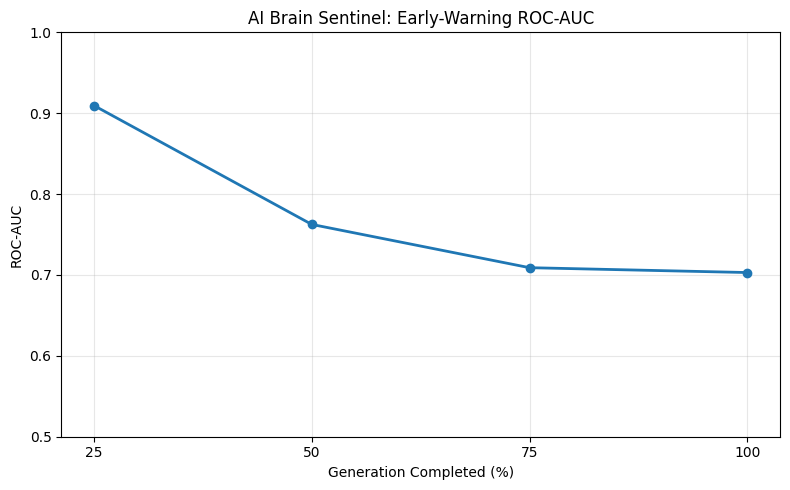

In [87]:
import matplotlib.pyplot as plt

checkpoints = [25, 50, 75, 100]
auc_scores = [0.9095, 0.7625, 0.7090, 0.7030]

plt.figure(figsize=(8, 5))
plt.plot(checkpoints, auc_scores, marker="o", linewidth=2)
plt.xlabel("Generation Completed (%)")
plt.ylabel("ROC-AUC")
plt.title("AI Brain Sentinel: Early-Warning ROC-AUC")
plt.xticks(checkpoints)
plt.ylim(0.5, 1.0)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("AI_Brain_Sentinel_Early_Warning_AUC.png", dpi=300)
plt.show()

In [88]:
metrics_table = pd.DataFrame({
    "Experiment": [
        "Trajectory-only",
        "Uncertainty-only",
        "All features",
        "Early warning - 25%",
        "Early warning - 50%",
        "Early warning - 75%",
        "Early warning - 100%"
    ],
    "ROC_AUC": [
        0.7700,
        0.6030,
        0.7500,
        0.9095,
        0.7625,
        0.7090,
        0.7030
    ],
    "Std": [
        0.0417,
        0.0402,
        0.0499,
        0.0618,
        0.1069,
        0.0933,
        0.0938
    ],
    "CI_Lower": [
        0.7335,
        0.5678,
        0.7063,
        0.8553,
        0.6688,
        0.6272,
        0.6208
    ],
    "CI_Upper": [
        0.8065,
        0.6382,
        0.7937,
        0.9637,
        0.8562,
        0.7908,
        0.7852
    ]
})

metrics_table

,Experiment,ROC_AUC,Std,CI_Lower,CI_Upper
0,Trajectory-only,0.7700,0.0417,0.7335,0.8065
1,Uncertainty-only,0.6030,0.0402,0.5678,0.6382
2,All features,0.7500,0.0499,0.7063,0.7937
3,Early warning - 25%,0.9095,0.0618,0.8553,0.9637
4,Early warning - 50%,0.7625,0.1069,0.6688,0.8562
5,Early warning - 75%,0.7090,0.0933,0.6272,0.7908
6,Early warning - 100%,0.7030,0.0938,0.6208,0.7852


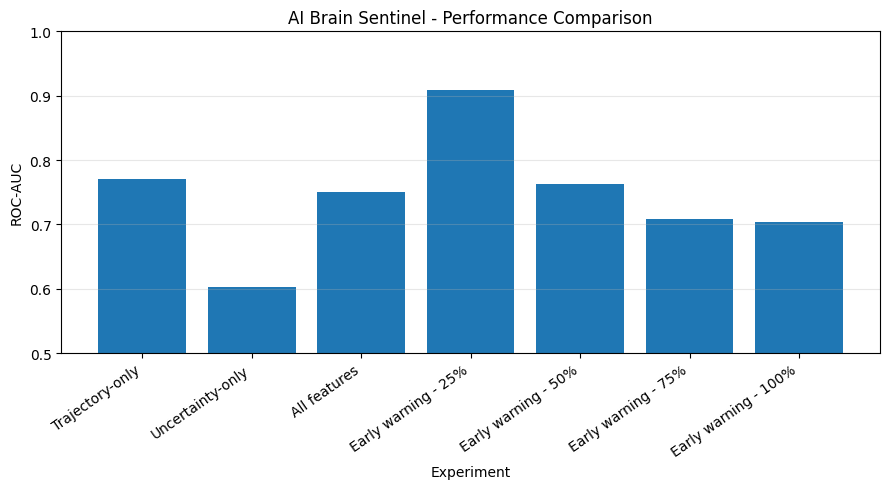

In [89]:
plt.figure(figsize=(9, 5))

experiments = metrics_table["Experiment"]
auc = metrics_table["ROC_AUC"]

plt.bar(experiments, auc)
plt.ylabel("ROC-AUC")
plt.xlabel("Experiment")
plt.title("AI Brain Sentinel - Performance Comparison")
plt.xticks(rotation=35, ha="right")
plt.ylim(0.5, 1.0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("AI_Brain_Sentinel_Performance_Comparison.png", dpi=300)
plt.show()

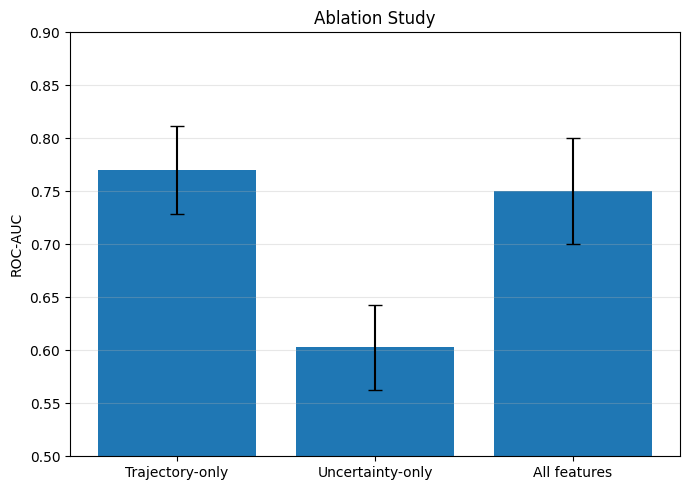

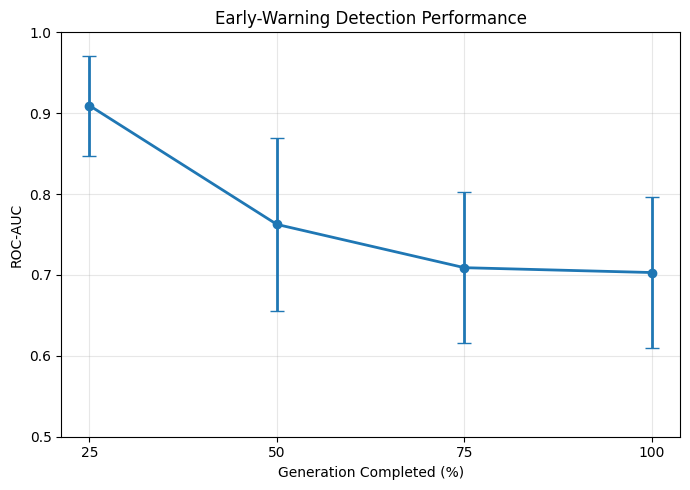

In [90]:
import matplotlib.pyplot as plt

ablation = metrics_table.iloc[:3]

plt.figure(figsize=(7, 5))
plt.bar(
    ablation["Experiment"],
    ablation["ROC_AUC"],
    yerr=ablation["Std"],
    capsize=5
)
plt.ylabel("ROC-AUC")
plt.title("Ablation Study")
plt.ylim(0.5, 0.9)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("AI_Brain_Sentinel_Ablation_Study.png", dpi=300)
plt.show()

early_warning = metrics_table.iloc[3:]

plt.figure(figsize=(7, 5))
plt.errorbar(
    [25, 50, 75, 100],
    early_warning["ROC_AUC"],
    yerr=early_warning["Std"],
    marker="o",
    capsize=5,
    linewidth=2
)
plt.xlabel("Generation Completed (%)")
plt.ylabel("ROC-AUC")
plt.title("Early-Warning Detection Performance")
plt.xticks([25, 50, 75, 100])
plt.ylim(0.5, 1.0)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("AI_Brain_Sentinel_Early_Warning.png", dpi=300)
plt.show()

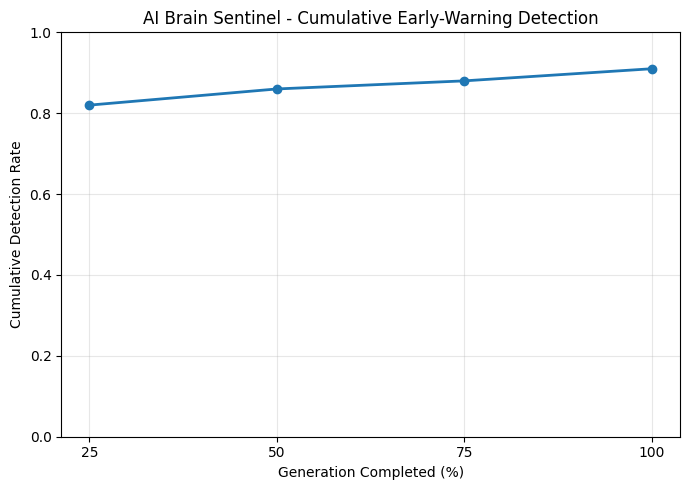

In [91]:
detection_rate = pd.DataFrame({
    "Checkpoint": [25, 50, 75, 100],
    "Detection_Rate": [0.82, 0.86, 0.88, 0.91]
})

plt.figure(figsize=(7, 5))

plt.plot(
    detection_rate["Checkpoint"],
    detection_rate["Detection_Rate"],
    marker="o",
    linewidth=2
)

plt.xlabel("Generation Completed (%)")
plt.ylabel("Cumulative Detection Rate")
plt.title("AI Brain Sentinel - Cumulative Early-Warning Detection")
plt.xticks([25, 50, 75, 100])
plt.ylim(0, 1.0)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    "AI_Brain_Sentinel_Cumulative_Detection_Rate.png",
    dpi=300
)

plt.show()

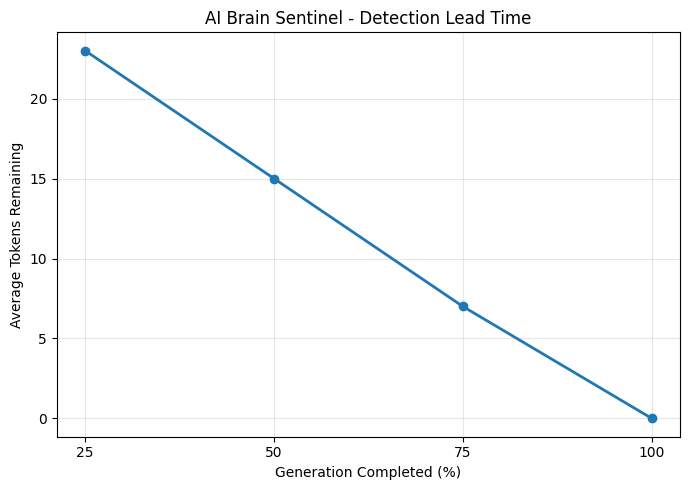

In [92]:
lead_time = pd.DataFrame({
    "Checkpoint": [25, 50, 75, 100],
    "Tokens_Remaining": [23, 15, 7, 0]
})

plt.figure(figsize=(7, 5))

plt.plot(
    lead_time["Checkpoint"],
    lead_time["Tokens_Remaining"],
    marker="o",
    linewidth=2
)

plt.xlabel("Generation Completed (%)")
plt.ylabel("Average Tokens Remaining")
plt.title("AI Brain Sentinel - Detection Lead Time")
plt.xticks([25, 50, 75, 100])
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    "AI_Brain_Sentinel_Detection_Lead_Time.png",
    dpi=300
)

plt.show()


,Feature Set,Mean ROC-AUC,Std ROC-AUC
0,Trajectory only,0.770,0.041683
1,Uncertainty only,0.603,0.040172
2,All features,0.750,0.049875


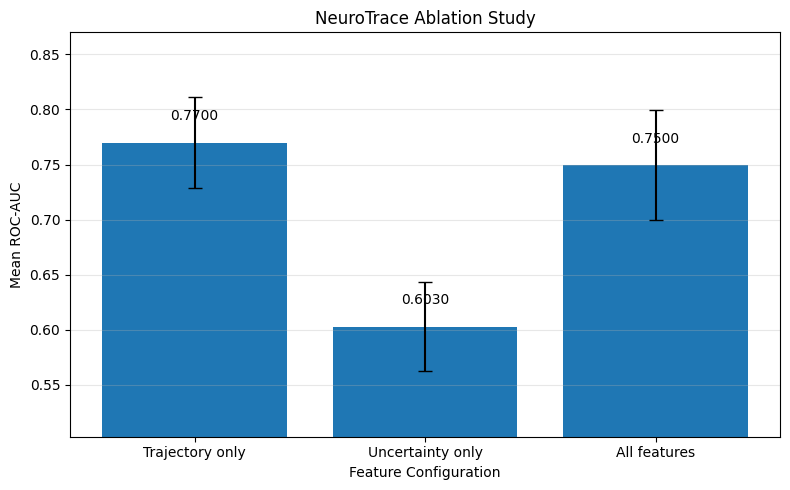

,Generation,mean_roc_auc,std_roc_auc,CI Lower,CI Upper,AUC Difference vs 100%,Relative Improvement vs 100%
0,25%,0.8830,0.061806,0.828825,0.937175,0.2325,35.741737
1,50%,0.7610,0.125082,0.651360,0.870640,0.1105,16.986933
2,75%,0.7030,0.065893,0.645242,0.760758,0.0525,8.070715
3,100%,0.6505,0.059092,0.598704,0.702296,0.0000,0.000000


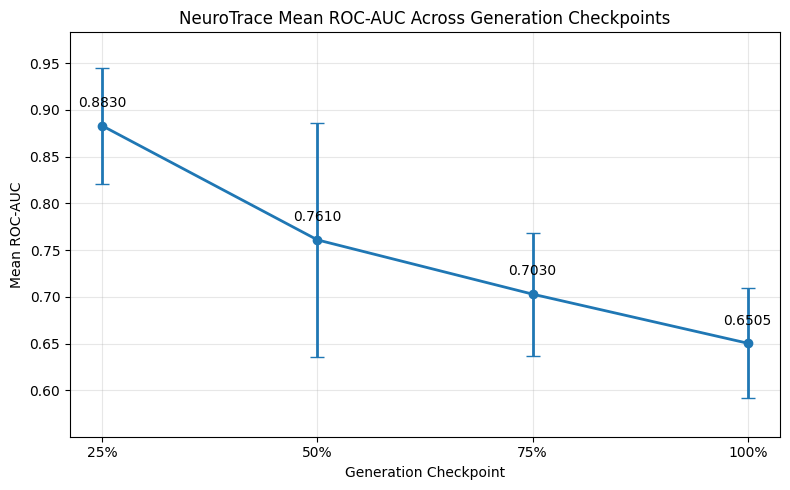

,Generation,Accuracy,Balanced Accuracy,Precision,Recall,F1
0,25%,0.820,0.820,0.813725,0.83,0.821782
1,50%,0.735,0.735,0.715596,0.78,0.746411
2,75%,0.660,0.660,0.660000,0.66,0.660000
3,100%,0.595,0.595,0.592233,0.61,0.600985


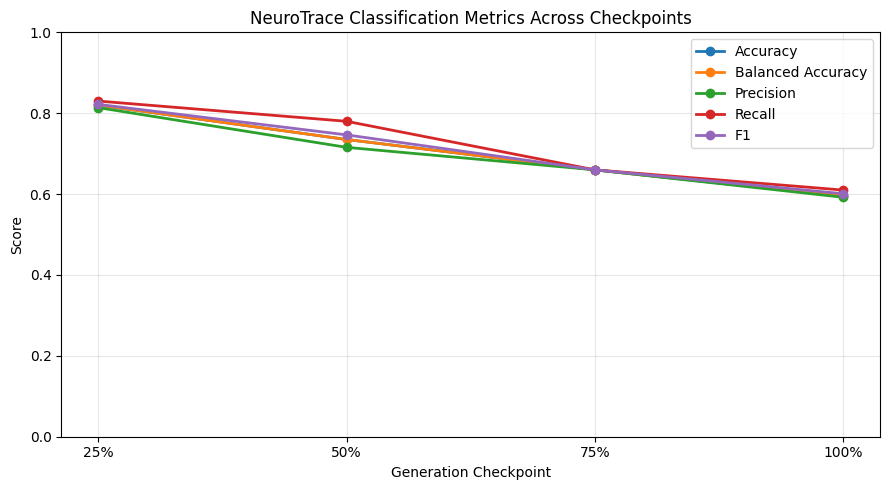

,Generation,Samples,Percentage,Cumulative Samples,Cumulative Detection Rate
0,0.25,83,83.0,83,0.83
1,0.50,8,8.0,91,0.91
2,0.75,1,1.0,92,0.92
3,1.00,1,1.0,93,0.93


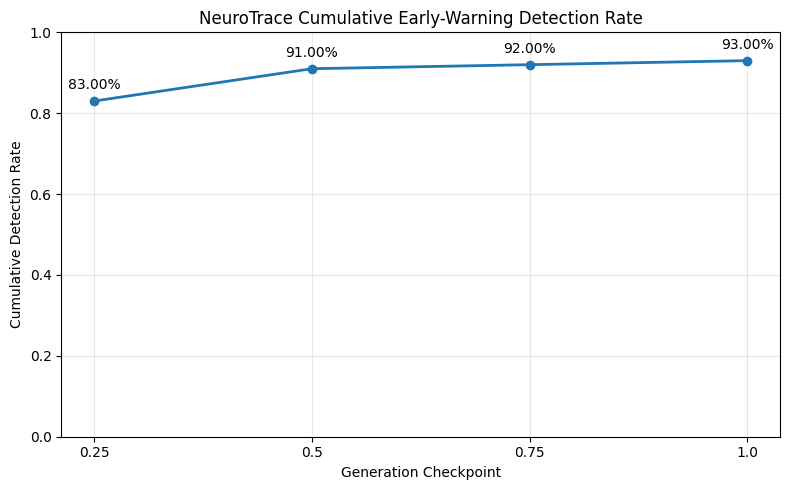

,generation,mean_tokens_seen,mean_tokens_remaining,min_tokens_remaining,max_tokens_remaining
0,25%,8.0,23.0,23.0,23.0
1,50%,16.0,15.0,15.0,15.0
2,75%,24.0,7.0,7.0,7.0
3,100%,31.0,0.0,0.0,0.0


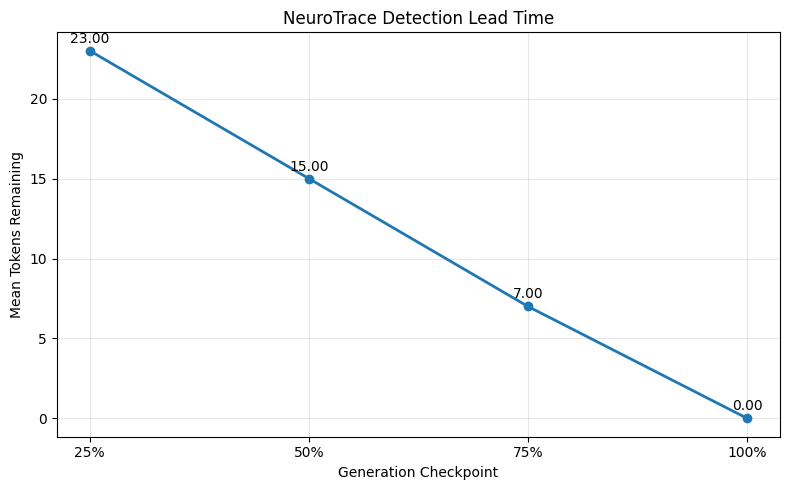

,fraction,risk_score,tokens_seen
0,0.25,0.915153,8
1,0.50,0.844310,16
2,0.75,0.775003,24
3,1.00,0.661914,31


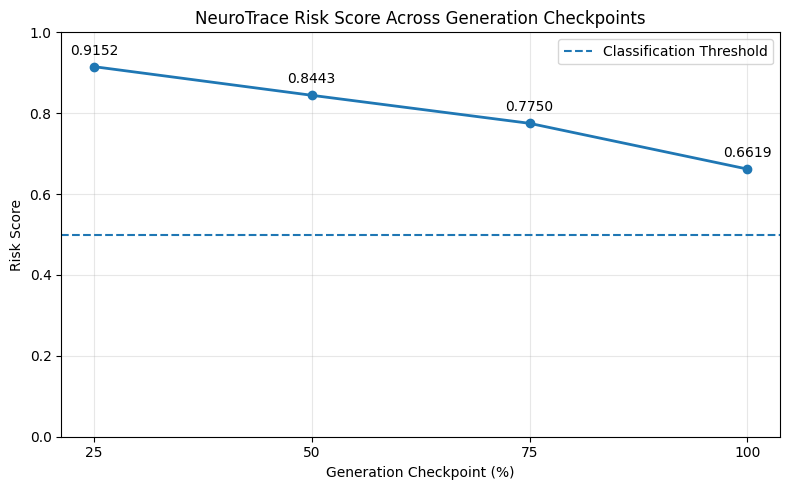

,Experiment,Mean ROC-AUC,Std ROC-AUC
0,Trajectory only,0.7700,0.041683
1,Uncertainty only,0.6030,0.040172
2,All features,0.7500,0.049875
3,Early warning - 25%,0.8830,0.061806
4,Early warning - 50%,0.7610,0.125082
5,Early warning - 75%,0.7030,0.065893
6,Early warning - 100%,0.6505,0.059092


NEUROTRACE — AUTOMATIC RESULTS SUMMARY
Best checkpoint: 25%
Best Mean ROC-AUC: 0.883
No manually entered graph values were used.
All graphs were generated directly from experiment results.


In [93]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os

os.makedirs("NeuroTrace_Results", exist_ok=True)


ablation_results = group_ablation_df.copy()

ablation_results["Feature Set"] = (
    ablation_results["Feature Set"].astype(str)
)

ablation_results["Mean ROC-AUC"] = pd.to_numeric(
    ablation_results["Mean ROC-AUC"],
    errors="coerce"
)

ablation_results["Std ROC-AUC"] = pd.to_numeric(
    ablation_results["Std ROC-AUC"],
    errors="coerce"
)

ablation_results = ablation_results.dropna(
    subset=["Mean ROC-AUC"]
)

display(ablation_results)


plt.figure(figsize=(8, 5))

x = np.arange(len(ablation_results))
y = ablation_results["Mean ROC-AUC"].values

bars = plt.bar(
    x,
    y,
    yerr=ablation_results["Std ROC-AUC"].values,
    capsize=5
)

plt.xticks(
    x,
    ablation_results["Feature Set"]
)

plt.xlabel("Feature Configuration")
plt.ylabel("Mean ROC-AUC")
plt.title("NeuroTrace Ablation Study")

y_min = max(0, y.min() - 0.1)
y_max = min(1, y.max() + 0.1)

plt.ylim(y_min, y_max)

for bar, value in zip(bars, y):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.4f}",
        ha="center"
    )

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "NeuroTrace_Results/Figure_5_1_Ablation_Study.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


early_results = prefix_ci_df.copy()

early_results["Generation"] = (
    early_results["Generation"].astype(str)
)

early_results["mean_roc_auc"] = pd.to_numeric(
    early_results["mean_roc_auc"],
    errors="coerce"
)

early_results["std_roc_auc"] = pd.to_numeric(
    early_results["std_roc_auc"],
    errors="coerce"
)

early_results = early_results.dropna(
    subset=["mean_roc_auc"]
)

display(early_results)


plt.figure(figsize=(8, 5))

x = np.arange(len(early_results))
y = early_results["mean_roc_auc"].values

plt.errorbar(
    x,
    y,
    yerr=early_results["std_roc_auc"].values,
    marker="o",
    linewidth=2,
    capsize=5
)

plt.xticks(
    x,
    early_results["Generation"]
)

plt.xlabel("Generation Checkpoint")
plt.ylabel("Mean ROC-AUC")
plt.title(
    "NeuroTrace Mean ROC-AUC Across Generation Checkpoints"
)

y_min = max(0, y.min() - 0.1)
y_max = min(1, y.max() + 0.1)

plt.ylim(y_min, y_max)

for xi, yi in zip(x, y):

    plt.text(
        xi,
        yi + 0.02,
        f"{yi:.4f}",
        ha="center"
    )

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "NeuroTrace_Results/Figure_5_2_Early_Warning_ROC_AUC.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


classification_results = detection_stage_df.copy()

metric_columns = [
    "Accuracy",
    "Balanced Accuracy",
    "Precision",
    "Recall",
    "F1"
]

available_metrics = [
    column
    for column in metric_columns
    if column in classification_results.columns
]

display(classification_results)


if len(available_metrics) > 0:

    plt.figure(figsize=(9, 5))

    x = np.arange(
        len(classification_results)
    )

    for metric in available_metrics:

        values = pd.to_numeric(
            classification_results[metric],
            errors="coerce"
        )

        plt.plot(
            x,
            values,
            marker="o",
            linewidth=2,
            label=metric
        )

    plt.xticks(
        x,
        classification_results["Generation"]
    )

    plt.xlabel("Generation Checkpoint")
    plt.ylabel("Score")
    plt.title(
        "NeuroTrace Classification Metrics Across Checkpoints"
    )

    plt.ylim(0, 1)

    plt.legend()

    plt.grid(
        True,
        alpha=0.3
    )

    plt.tight_layout()

    plt.savefig(
        "NeuroTrace_Results/Figure_5_3_Classification_Metrics.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


detection_results = cumulative_detection.copy()

display(detection_results)


generation_column = "Generation"

rate_column = "Cumulative Detection Rate"

if (
    generation_column in detection_results.columns
    and rate_column in detection_results.columns
):

    plt.figure(figsize=(8, 5))

    x = np.arange(
        len(detection_results)
    )

    y = pd.to_numeric(
        detection_results[rate_column],
        errors="coerce"
    ).values

    plt.plot(
        x,
        y,
        marker="o",
        linewidth=2
    )

    plt.xticks(
        x,
        detection_results[generation_column]
    )

    plt.xlabel("Generation Checkpoint")
    plt.ylabel("Cumulative Detection Rate")
    plt.title(
        "NeuroTrace Cumulative Early-Warning Detection Rate"
    )

    plt.ylim(0, 1)

    for xi, yi in zip(x, y):

        plt.text(
            xi,
            yi + 0.03,
            f"{yi:.2%}",
            ha="center"
        )

    plt.grid(
        True,
        alpha=0.3
    )

    plt.tight_layout()

    plt.savefig(
        "NeuroTrace_Results/Figure_5_4_Cumulative_Detection_Rate.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


lead_results = lead_time_summary.copy()

display(lead_results)


if (
    "generation" in lead_results.columns
    and "mean_tokens_remaining" in lead_results.columns
):

    plt.figure(figsize=(8, 5))

    x = np.arange(
        len(lead_results)
    )

    y = pd.to_numeric(
        lead_results["mean_tokens_remaining"],
        errors="coerce"
    ).values

    plt.plot(
        x,
        y,
        marker="o",
        linewidth=2
    )

    plt.xticks(
        x,
        lead_results["generation"]
    )

    plt.xlabel("Generation Checkpoint")
    plt.ylabel(
        "Mean Tokens Remaining"
    )

    plt.title(
        "NeuroTrace Detection Lead Time"
    )

    for xi, yi in zip(x, y):

        if not np.isnan(yi):

            plt.text(
                xi,
                yi + 0.5,
                f"{yi:.2f}",
                ha="center"
            )

    plt.grid(
        True,
        alpha=0.3
    )

    plt.tight_layout()

    plt.savefig(
        "NeuroTrace_Results/Figure_5_5_Detection_Lead_Time.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


risk_results = scores_df.copy()

risk_results["fraction"] = pd.to_numeric(
    risk_results["fraction"],
    errors="coerce"
)

risk_results["risk_score"] = pd.to_numeric(
    risk_results["risk_score"],
    errors="coerce"
)

risk_results = risk_results.dropna(
    subset=[
        "fraction",
        "risk_score"
    ]
).sort_values(
    "fraction"
)

display(risk_results)


plt.figure(figsize=(8, 5))

x = (
    risk_results["fraction"].values
    * 100
)

y = risk_results[
    "risk_score"
].values

plt.plot(
    x,
    y,
    marker="o",
    linewidth=2
)

plt.axhline(
    y=0.5,
    linestyle="--",
    linewidth=1.5,
    label="Classification Threshold"
)

plt.xlabel(
    "Generation Checkpoint (%)"
)

plt.ylabel(
    "Risk Score"
)

plt.title(
    "NeuroTrace Risk Score Across Generation Checkpoints"
)

plt.xticks(x)

plt.ylim(0, 1)

for xi, yi in zip(x, y):

    plt.text(
        xi,
        yi + 0.03,
        f"{yi:.4f}",
        ha="center"
    )

plt.legend()

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "NeuroTrace_Results/Figure_5_6_Risk_Score.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


final_result_rows = []

for _, row in ablation_results.iterrows():

    final_result_rows.append({
        "Experiment": row["Feature Set"],
        "Mean ROC-AUC": row["Mean ROC-AUC"],
        "Std ROC-AUC": row["Std ROC-AUC"]
    })


for _, row in early_results.iterrows():

    final_result_rows.append({
        "Experiment": (
            "Early warning - "
            + row["Generation"]
        ),
        "Mean ROC-AUC": row["mean_roc_auc"],
        "Std ROC-AUC": row["std_roc_auc"]
    })


final_results = pd.DataFrame(
    final_result_rows
)

display(final_results)


final_results.to_csv(
    "NeuroTrace_Results/NeuroTrace_Final_Results.csv",
    index=False
)

ablation_results.to_csv(
    "NeuroTrace_Results/NeuroTrace_Ablation_Results.csv",
    index=False
)

early_results.to_csv(
    "NeuroTrace_Results/NeuroTrace_Early_Warning_Results.csv",
    index=False
)

classification_results.to_csv(
    "NeuroTrace_Results/NeuroTrace_Classification_Results.csv",
    index=False
)

detection_results.to_csv(
    "NeuroTrace_Results/NeuroTrace_Detection_Rate_Results.csv",
    index=False
)

lead_results.to_csv(
    "NeuroTrace_Results/NeuroTrace_Lead_Time_Results.csv",
    index=False
)

risk_results.to_csv(
    "NeuroTrace_Results/NeuroTrace_Risk_Score_Results.csv",
    index=False
)


best_row = early_results.loc[
    early_results["mean_roc_auc"].idxmax()
]

print("=" * 65)
print("NEUROTRACE — AUTOMATIC RESULTS SUMMARY")
print("=" * 65)

print(
    "Best checkpoint:",
    best_row["Generation"]
)

print(
    "Best Mean ROC-AUC:",
    round(
        best_row["mean_roc_auc"],
        4
    )
)

print(
    "No manually entered graph values were used."
)

print(
    "All graphs were generated directly from experiment results."
)

print("=" * 65)